# Lens benchmarks with per-layer bootstrap intervals — Gemma 4 E4B

**Question.** How do J-lens and logit-lens intermediate readouts vary with depth,
and how uncertain are their scores and paired differences at each block?

**Answer (this run: `google/gemma-4-E4B` at `411aa17`, bfloat16, BOS from the tokenizer, prefitted lens `neuronpedia/jacobian-lens/gemma-4-e4b/jlens/Salesforce-wikitext/gemma-4-E4B_jacobian_lens.pt` at `9fa267f`; RTX 4090).** Read block by block (pass@10 at a single block, 42 blocks), the J-lens advantage is concentrated in the middle of the network on the latent bridge, while on most other datasets both lenses peak late and the logit lens catches up or leads in some late blocks:

| dataset | J-lens peak (block, depth) | logit-lens peak | blocks with J − logit CI > 0 | blocks with CI < 0 |
|---|---|---|---|---|
| latent bridge: all but slot | 0.88 (18, 44%) | 0.19 (40, 98%) | 24 (between 4 and 40) | 1 (31) |
| latent bridge: country token | 0.72 (18, 44%) | 0.01 (33, 80%) | 14 (between 5 and 21) | 1 (33) |
| latent bridge: subject | 0.32 (20, 49%) | 0.04 (33, 80%) | 26 (between 4 and 39) | 0 |
| multihop-easy | 0.54 (40, 98%) | 0.39 (40, 98%) | 17 (between 11 and 40) | 3 (31–34) |
| typo | 0.27 (21, 51%) | 0.20 (34, 83%) | 19 (between 5 and 39) | 5 (30–34) |
| multilingual | 0.21 (34, 83%) | 0.31 (34, 83%) | 16 (between 10 and 40) | 10 (29–39) |
| multihop | 0.39 (36, 88%) | 0.38 (37, 90%) | 4 (between 16 and 28) | 0 |
| order-ops | 0.30 (38, 93%) | 0.30 (38, 93%) | 9 (between 0 and 34) | 0 |
| association, poetry | ≤ 0.04 | ≤ 0.01 | 0 | 0 |

Peaks exclude the shared final block (block 41), where both lenses agree by construction. Intervals are pointwise 95% paired-bootstrap intervals (10,000 resamples) and are not corrected for testing 41 blocks; isolated significant blocks should be read as exploratory.

The inner-layer (best-block) scores reproduce [the bootstrap notebook](latent_bridge_v2_lens_benchmark_bootstrap.ipynb) to within about 1.3 percentage points, not exactly: that run used an RTX A6000 and this one an RTX 4090. With identical code, settings and data, bf16 GPU kernels differ between the two cards, which shifts near-tied ranks and even one of the model's own answers (latent-bridge brand: 79 vs 78 correct). Compare models using runs from one source where exact agreement matters.

This version retains the original inner-layer pass@k/AUC analysis and adds
**pointwise per-layer confidence intervals** for both readouts and their paired
difference, covering three latent-bridge spans and every single-position dataset.
The final block is included. Bootstrap results are cached separately from model
passes. CSV exports contain the exact plotted values, model provenance, coverage,
zero-based layer indices, and normalized depth for later comparisons across models.
Set `PRINT_LAYERWISE_CSV=True` to also print the full plotting CSV in the notebook.


## Method and interpretation

* **Latent bridge:** keep `[block, token position]` ranks for the country, a different same-family control country, and the target language. Min-reduce over subject, country token(s), other template, last, slot, all-but-slot, or all positions. Character offsets define spans even when words split into multiple tokens. The slot is the final token of `in`/`from` before `a country`, where the country would be a literal next-word prediction. Inner layers exclude the final block.
* **Anthropic datasets:** use the readout positions in [the local protocol](../../data/evaluations/README.md): multihop, multilingual, order-ops, association and typo use the final prompt token; poetry uses the last newline token. Do not sweep positions for their protocol scores. Report the protocol's all-layer result as well as inner-layer and final-output diagnostics.
* **Multihop-easy:** use the final prompt token, with no order-ops synonym expansion. Average word hits within a prompt, phrasings within `base_id`, base items within each family, then families equally. Retain `group_id` and dev/test labels; report all/dev/test separately. These are unfiltered candidates, not established small-model successes. Hop diagnostic prompts are metadata only and are never appended to evaluation context.
* **Scoring:** rank the best exact decoded whole-token spelling, accepting case and leading-space variants; order-ops also expands number/operation synonyms. No prefix fallback. Unsupported annotations retain null ranks and are excluded, with word and item coverage shown. Scores average word hits within each item, then weight eligible items equally. Controls are descriptive baselines, not calibrated chance probabilities.
* **Readout:** final norm, LM head and optional softcap belong to the adapter. Lexical ranks use pre-softcap scores and ascending token ID to break ties; model correctness uses the actual distribution argmax. Both lenses share the untransported final block.
* **Encoding:** preserve source whitespace, use the configured BOS policy, apply no chat template, and reject overlength prompts. Thus trailing spaces may form the final token. These strict semantics can differ from older notebooks that stripped prompts or accepted answer prefixes; these results are an adaptation, not an exact reproduction of Anthropic's model or published numbers.
* **Compute:** sort by length and right-pad with masks when supported, otherwise group equal lengths. Each batch shares one model pass across lenses. Chunk vocabulary readouts; retain only ranks between batches. Full batch activations and one fp32 Jacobian per inner block still consume memory.

## Repository setup (local or Colab)

In a fresh Colab session, clone this GitHub fork; reuse an existing clone with
`git pull --ff-only` and install its dependencies into the active Python environment.
A notebook opened inside a local checkout uses that checkout directly. Clone, pull,
and installation errors stop the setup cell. Run this cell before importing `jlens`;
if you already imported an older version in this session, restart the runtime first.

In [1]:
import hashlib
import json
import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/ai360-project-school-j-lens/jacobian-lens-gpt2.git"
IN_COLAB = "COLAB_RELEASE_TAG" in os.environ or "google.colab" in sys.modules

# Reuse a checkout when opened locally, including from a nested notebook folder.
local_repo = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "jlens" / "evaluation.py").is_file()),
    None,
)
REPO_DIR = local_repo or Path.cwd() / "jacobian-lens-gpt2"
if local_repo is not None:
    if IN_COLAB:
        subprocess.run(["git", "-C", str(REPO_DIR), "pull", "--ff-only"], check=True)
elif REPO_DIR.exists():
    subprocess.run(["git", "-C", str(REPO_DIR), "pull", "--ff-only"], check=True)
else:
    subprocess.run(["git", "clone", REPO_URL, str(REPO_DIR)], check=True)

REPO = REPO_DIR.resolve()
if IN_COLAB:
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "-e", str(REPO)], check=True,
    )
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
if not (REPO / "jlens" / "position_benchmark.py").is_file():
    raise RuntimeError("Update this checkout to the revision containing jlens/position_benchmark.py.")
print(f"Repository ready: {REPO.name}")

Repository ready: jacobian-lens-gpt2


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import transformers
from IPython.display import Markdown, display
from transformers import AutoConfig, AutoModelForCausalLM, AutoTokenizer

import jlens
from jlens.batched_evaluation import evaluate_paired_batched
from jlens.evaluation import DATASETS, identity_lens, load_eval, pass_at_k
from jlens.position_benchmark import (
    evaluate_position_ranks,
    latent_bridge_spans,
    load_latent_bridge,
    reduce_position_ranks,
)
from jlens.strict_scoring import DecodedSpellings, ExplicitPromptModel

pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)

## Configuration and cache-only mode

Set `RUN_MODE="cache"` and `EXISTING_RANK_CACHE` to the exact trusted `results.pkl`
from an earlier model-agnostic/GPT-2/Gemma benchmark. The source manifest supplies
model identity, tokenizer serialization, BOS, dtype, and scoring provenance.
Current model defaults are ignored. This path makes no Hub requests and never
falls back to inference. Keep the original cache unmodified.

New caches embed dataset/group metadata. For old caches, the notebook reconstructs
the selected prompt sets from this checkout and verifies their hash against the
source manifest before using multihop-easy grouping. If the dataset changed,
restore the matching source data; do not silently apply new labels to old ranks.

`smoke` is an offline tiny-model check. `pretrained` retains the original pinned
lens download and model evaluation. Bootstrap settings are separate from the
inference cache key. Changing only those settings does not require inference.

The layerwise analysis reuses these same ranks and model settings. It evaluates
all `K_VALUES` at each block; figures show `K` (10 by default). The additional
CPU bootstrap work is cached, so a rerun restores both aggregate and per-layer
interval tables when the analysis inputs are unchanged.


In [3]:
RUN_MODE = os.environ.get("JLENS_BENCHMARK_MODE", "pretrained")  # "smoke", "cache", or "pretrained"
EXISTING_RANK_CACHE = os.environ.get("JLENS_RANK_CACHE", "")  # Existing benchmark results.pkl.
MODEL_ID = os.environ.get("JLENS_MODEL_ID", "google/gemma-4-E4B")
MODEL_REVISION = "411aa17b749aa952df1359d2dcea73917a544d9a"  # Hub commit of the evaluated snapshot.
LENS_PATH = Path(os.environ.get(
    "JLENS_LENS_PATH", REPO / "runs/gpt2-xl-convergence/snapshot_lens_134.pt",
)).expanduser()
# Same pinned artifacts as the model-agnostic token-swap notebook.
HUB_LENS_FILES = {
    "Qwen/Qwen3-4B": "qwen3-4b/jlens/Salesforce-wikitext/Qwen3-4B_jacobian_lens.pt",
    "Qwen/Qwen3-1.7B": "qwen3-1.7b/jlens/Salesforce-wikitext/Qwen3-1.7B_jacobian_lens.pt",
    "openai-community/gpt2": "gpt2-small/jlens/Salesforce-wikitext/gpt2_jacobian_lens.pt",
    "google/gemma-4-31B": "gemma-4-31b/jlens/Salesforce-wikitext/gemma-4-31B_jacobian_lens.pt",
    "Qwen/Qwen3.5-9B-Base": "qwen3.5-9b-pt/jlens/Salesforce-wikitext/Qwen3.5-9B-Base_jacobian_lens.pt",
    "Qwen/Qwen3.5-4B": "qwen3.5-4b/jlens/Salesforce-wikitext/Qwen3.5-4B_jacobian_lens_n1000.pt",
    "google/gemma-4-E4B": "gemma-4-e4b/jlens/Salesforce-wikitext/gemma-4-E4B_jacobian_lens.pt",
}
HUB_LENS = (
    dict(repo_id="neuronpedia/jacobian-lens", filename=HUB_LENS_FILES[MODEL_ID],
         revision="9fa267f841d62aa468dab5b9b38c3dc45a82d863")
    if MODEL_ID in HUB_LENS_FILES else None
)
LENS_SOURCE = "hub" if HUB_LENS is not None and not os.environ.get("JLENS_LENS_PATH") else "local"
# Override HUB_LENS for another published artifact; select LENS_SOURCE explicitly.
FIT_PROVENANCE = {
    "model_id": MODEL_ID,
    "model_revision": None,
    # From the artifact's config.yaml (Neuronpedia fit_lens.py).
    "dtype": "bfloat16",
    "corpus_mix": "Salesforce/wikitext wikitext-103-raw-v1 (train), max 2000 chars; 663 of 1000 prompts fitted",
    "sequence_length": 128,
    "dimension_batch_size": 128,
}
# Keep GPT-2 BOS behavior; other presets use their native tokenizer policy.
BOS_POLICY = "prepend" if MODEL_ID.startswith("openai-community/gpt2") else "tokenizer"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.bfloat16  # as the lens was fitted, and as in the other Qwen/Gemma runs
BATCH_SIZE = 8
MAX_BATCH_TOKENS = 1024
MAX_SEQ_LEN = 512
POSITION_CHUNK_SIZE = 8
RANK_CHUNK_SIZE = 8
K_VALUES = [1, 2, 5, 10, 20, 50, 100]
K = 10
SMOKE_ITEMS_PER_DATASET = 2
CACHE_ROOT = REPO / "runs/model-agnostic-lens-benchmark"
FORCE_RECOMPUTE = False
COLORS = {"logit lens": "#eb6834", "J-lens": "#2a78d6"}

if RUN_MODE not in {"smoke", "cache", "pretrained"}:
    raise ValueError("RUN_MODE must be smoke, cache, or pretrained")

In [4]:
from jlens.bootstrap import retrieval_bootstrap, retrieval_bootstrap_by_layer

BOOTSTRAP_OPTIONS = dict(
    n_resamples=int(os.environ.get("JLENS_BOOTSTRAP_RESAMPLES", "10000")),
    confidence=0.95, seed=0, batch_size=256,
)
LAYERWISE_SPANS = ["subject", "country token", "all but slot"]
PRINT_LAYERWISE_CSV = False  # CSV files are always written; enable for copy/paste.
if K not in K_VALUES:
    raise ValueError("The plotted K must be in K_VALUES")


In [5]:
latent_evals = load_latent_bridge(REPO)
anthropic_evals = {dataset: load_eval(str(REPO), dataset) for dataset in [*DATASETS, "multihop-easy"]}
full_counts = {name: len(items) for name, items in {**latent_evals, **anthropic_evals}.items()}
if RUN_MODE == "smoke":
    latent_evals = {name: items[:SMOKE_ITEMS_PER_DATASET] for name, items in latent_evals.items()}
    easy_frame = pd.DataFrame(anthropic_evals["multihop-easy"])
    smoke_bases = easy_frame.drop_duplicates("family").base_id
    anthropic_evals = {
        name: ([item for item in items if item["base_id"] in set(smoke_bases)]
               if name == "multihop-easy" else items[:SMOKE_ITEMS_PER_DATASET])
        for name, items in anthropic_evals.items()
    }

CACHED_PAYLOAD = None
if RUN_MODE == "cache":
    if not EXISTING_RANK_CACHE:
        raise ValueError("Set EXISTING_RANK_CACHE to a saved benchmark results.pkl")
    SOURCE_CACHE_PATH = Path(EXISTING_RANK_CACHE).expanduser().resolve()
    CACHED_PAYLOAD = pd.read_pickle(SOURCE_CACHE_PATH)
    required = {"manifest", "position_words", "latent_items", "anth_words", "anth_items", "spans", "n_layers"}
    if not isinstance(CACHED_PAYLOAD, dict) or required - set(CACHED_PAYLOAD):
        raise ValueError("Expected a complete benchmark rank cache, not an aggregate CSV")
    sidecar = SOURCE_CACHE_PATH.parent / "manifest.json"
    # JSON converts integer config keys (e.g. id2label) to strings.
    normalized_manifest = json.loads(json.dumps(CACHED_PAYLOAD["manifest"], default=str))
    if sidecar.exists() and json.loads(sidecar.read_text()) != normalized_manifest:
        raise ValueError("Rank cache and sidecar manifest disagree")
    if "evals" in CACHED_PAYLOAD:
        selected = CACHED_PAYLOAD["evals"]
        latent_evals = {name: rows for name, rows in selected.items() if name.startswith("latent-bridge/")}
        anthropic_evals = {name: rows for name, rows in selected.items() if not name.startswith("latent-bridge/")}
    else:
        def cached_subset(evals, items):
            names = items.groupby("dataset").item.agg(set).to_dict()
            selected = {name: [item for item in rows if item["name"] in names[name]]
                        for name, rows in evals.items() if name in names}
            if any({item["name"] for item in selected.get(name, [])} != keys for name, keys in names.items()):
                raise ValueError("Cached prompt IDs are absent from the current datasets")
            return selected
        latent_evals = cached_subset(latent_evals, CACHED_PAYLOAD["latent_items"])
        anthropic_evals = cached_subset(anthropic_evals, CACHED_PAYLOAD["anth_items"])
    selected = {**latent_evals, **anthropic_evals}
    data_hash = hashlib.sha256(json.dumps(selected, sort_keys=True, default=str).encode()).hexdigest()
    if data_hash != CACHED_PAYLOAD["manifest"]["evals_sha256"]:
        raise ValueError("Dataset/group metadata changed since this cache; restore the matching source data")

easy_metadata = pd.DataFrame(anthropic_evals["multihop-easy"])[
    ["name", "base_id", "family", "group_id", "split", "template_id"]
].rename(columns={"name": "item"})
assert easy_metadata.groupby("base_id").size().eq(2).all()
selected_evals = {**latent_evals, **anthropic_evals}
display(pd.DataFrame([
    {"dataset": name, "available": full_counts[name], "selected": len(items),
     "annotated_intermediates": sum(len(item["intermediates"]) for item in items),
     "annotated_targets": sum("target" in item for item in items)}
    for name, items in selected_evals.items()
]).set_index("dataset"))

,available,selected,annotated_intermediates,annotated_targets
dataset,,,,
latent-bridge/landmark,108,108,108,108
latent-bridge/city,119,119,119,119
latent-bridge/person,117,117,117,117
latent-bridge/brand,83,83,83,83
latent-bridge/food,103,103,103,103
multihop,93,93,103,93
multilingual,107,107,428,107
order-ops,55,55,110,55
poetry,98,98,98,0


In [6]:
if RUN_MODE == "cache":
    LENS_PROVENANCE = CACHED_PAYLOAD["manifest"].get("lens_artifact", {})
    RESOLVED_LENS_PATH = None
    print("Cache-only: lens loading skipped.")
else:
    from jlens.artifact_provenance import download_lens_artifact

    # Clear a previous resolution before a failed or interrupted rerun.
    RESOLVED_LENS_PATH = None
    LENS_PROVENANCE = None
    if RUN_MODE == "smoke":
        LENS_PROVENANCE = {"source": "identity", "fitting_provenance": "no fitting"}
    else:
        if FIT_PROVENANCE["model_id"] != MODEL_ID:
            raise ValueError("Lens provenance model_id differs from MODEL_ID")
        if LENS_SOURCE == "hub":
            if not HUB_LENS:
                raise ValueError(f"No Hub preset for {MODEL_ID}; supply HUB_LENS or use a local lens.")
            artifact = download_lens_artifact(**HUB_LENS)
            RESOLVED_LENS_PATH = Path(artifact.path)
            LENS_PROVENANCE = {"source": "hub", **artifact.to_dict()}
        elif LENS_SOURCE == "local":
            local_path = Path(LENS_PATH).expanduser().resolve()
            if not local_path.is_file():
                raise FileNotFoundError(f"Set LENS_PATH to a fitted lens for {MODEL_ID}: {local_path}")
            RESOLVED_LENS_PATH = local_path
            LENS_PROVENANCE = {"source": "local", "path": str(local_path),
                               "fitting_provenance": "user-supplied; see FIT_PROVENANCE"}
        else:
            raise ValueError("LENS_SOURCE must be hub or local")
    display(LENS_PROVENANCE)

{'source': 'hub',
 'repo_id': 'neuronpedia/jacobian-lens',
 'filename': 'gemma-4-e4b/jlens/Salesforce-wikitext/gemma-4-E4B_jacobian_lens.pt',
 'requested_revision': '9fa267f841d62aa468dab5b9b38c3dc45a82d863',
 'resolved_revision': '9fa267f841d62aa468dab5b9b38c3dc45a82d863',
 'sha256': '119301db1ce48d8c5e1c9f1d374625bd8672c9522a7abb88834b1ca2a260165d',
 'size': 537408054,
 'path': '/workspace/.hf_home/hub/models--neuronpedia--jacobian-lens/snapshots/9fa267f841d62aa468dab5b9b38c3dc45a82d863/gemma-4-e4b/jlens/Salesforce-wikitext/gemma-4-E4B_jacobian_lens.pt',
 'verification': 'Hub LFS size and SHA-256 at resolved revision',
 'fitting_provenance': 'unverified legacy final lens'}

## Model identity and cache provenance

The cache key covers the selected prompts, model/config revision, full tokenizer serialization, BOS/dtype/device, lens SHA-256 and Hub receipt, fit metadata, chunk settings, relevant implementation files, package versions and notebook code. Editing an input or scoring implementation creates a separate run directory. A cache hit skips model weight loading and all forwards; plots and summaries are rebuilt from the saved ranks. Cached `.pkl`, `.pt` and generated figures live in ignored `runs/`.

In [7]:
import re

from huggingface_hub import HfApi


def digest_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for chunk in iter(lambda: stream.read(8 * 1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def digest_json(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, default=str).encode()).hexdigest()


if RUN_MODE == "cache":
    from types import SimpleNamespace

    from tokenizers import Tokenizer

    manifest = CACHED_PAYLOAD["manifest"]
    SOURCE_MODE = manifest["mode"]
    run_model_id, resolved_revision = manifest["model"], manifest["revision"]
    run_dtype, BOS_POLICY = manifest["dtype"], manifest["bos_policy"]
    # Reconstruct only the saved decoder, in memory; no tokenizer download.
    backend = Tokenizer.from_str(manifest["tokenizer"])
    tokenizer = SimpleNamespace(decode=lambda ids: backend.decode(list(ids), skip_special_tokens=False))
    text_config = manifest["config"].get("text_config", manifest["config"])
    config = SimpleNamespace(get_text_config=lambda: SimpleNamespace(vocab_size=text_config["vocab_size"]))
    CACHE_PATH = SOURCE_CACHE_PATH
    print(f"Cache-only source: {SOURCE_MODE}; model: {run_model_id}; revision: {resolved_revision}")
else:
    if RUN_MODE == "smoke":
        from tokenizers import Regex, Tokenizer, models, pre_tokenizers
        from transformers import LlamaConfig, PreTrainedTokenizerFast

        # Preserve newlines as tokens so poetry's readout is exercised offline.
        splitter = pre_tokenizers.Sequence([
            pre_tokenizers.Split(Regex(r"\n"), behavior="isolated"),
            pre_tokenizers.Split(Regex(r"[^\S\n]+"), behavior="removed"),
        ])
        texts = [item["prompt"] for items in selected_evals.values() for item in items]
        labels = [word for items in selected_evals.values() for item in items
                  for word in [*item["intermediates"], *item.get("controls", []), item.get("target", "")]]
        pieces = {piece for text in texts + labels for piece, _ in splitter.pre_tokenize_str(text)}
        vocab = {token: i for i, token in enumerate(["[UNK]", "[BOS]", "[PAD]", *sorted(pieces)])}
        backend = Tokenizer(models.WordLevel(vocab, unk_token="[UNK]"))
        backend.pre_tokenizer = splitter
        tokenizer = PreTrainedTokenizerFast(
            tokenizer_object=backend, unk_token="[UNK]", bos_token="[BOS]", pad_token="[PAD]",
        )
        config = LlamaConfig(
            vocab_size=len(tokenizer), hidden_size=16, intermediate_size=32,
            num_hidden_layers=3, num_attention_heads=2, num_key_value_heads=1,
            max_position_embeddings=MAX_SEQ_LEN, bos_token_id=tokenizer.bos_token_id,
            pad_token_id=tokenizer.pad_token_id, eos_token_id=None,
        )
        run_model_id, resolved_revision = "offline/random-tiny-llama", "seed-0"
        lens_identity = "identity-matrices-v1"
        fit_metadata = {"method": "identity; no fitting", "corpus_mix": None,
                        "sequence_length": None, "dimension_batch_size": None}
        run_device, run_dtype = "cpu", torch.float32
    else:
        if FIT_PROVENANCE["model_id"] != MODEL_ID:
            raise ValueError("Lens provenance model_id differs from MODEL_ID")
        # Resolve before loading so config, tokenizer and weights share one commit.
        resolved_revision = HfApi().model_info(MODEL_ID, revision=MODEL_REVISION).sha
        if not isinstance(resolved_revision, str) or not re.fullmatch(r"[0-9a-f]{40}", resolved_revision):
            raise ValueError("The Hub did not return an immutable model revision")
        config = AutoConfig.from_pretrained(MODEL_ID, revision=resolved_revision)
        tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=resolved_revision, use_fast=True)
        if FIT_PROVENANCE["model_revision"] not in {None, resolved_revision}:
            raise ValueError("Lens provenance revision differs from the selected model")
        run_model_id = MODEL_ID
        lens_identity = (LENS_PROVENANCE["sha256"] if LENS_SOURCE == "hub"
                         else digest_file(RESOLVED_LENS_PATH))
        fit_metadata = FIT_PROVENANCE.copy()
        run_device, run_dtype = DEVICE, DTYPE
    if not tokenizer.is_fast:
        raise ValueError("This benchmark requires fast-tokenizer offsets for latent spans")

    implementation = [
        "jlens/position_benchmark.py", "jlens/batched_evaluation.py", "jlens/evaluation.py",
        "jlens/artifact_provenance.py", "jlens/hf.py", "jlens/readout.py", "jlens/strict_scoring.py", "jlens/lens.py", "jlens/hooks.py",
    ]
    notebook_path = REPO / "notebooks/model_agnostic/latent_bridge_v2_lens_benchmark_bootstrap_layerwise.ipynb"
    notebook_code = ["".join(cell["source"]) for cell in json.loads(notebook_path.read_text())["cells"]
                     if cell["cell_type"] == "code" and cell["id"] in {"benchmark-repository-setup", "08149f1d", "ca578419", "ea930c3e", "benchmark-lens-source", "c1eb4c15", "e435187a"}]
    manifest = {
        "schema": 1, "mode": RUN_MODE, "model": run_model_id, "revision": resolved_revision,
        "config": config.to_dict(), "tokenizer": tokenizer.backend_tokenizer.to_str(),
        "special_tokens": tokenizer.special_tokens_map, "bos_policy": BOS_POLICY,
        "dtype": str(run_dtype), "device": run_device, "lens_sha256_or_identity": lens_identity,
        "lens_artifact": {k: v for k, v in LENS_PROVENANCE.items() if k != "path"},
        "fit": fit_metadata, "evals_sha256": digest_json(selected_evals),
        "implementation": {name: digest_file(REPO / name) for name in implementation},
        "notebook_code_sha256": digest_json(notebook_code),
        "versions": {"torch": torch.__version__, "transformers": transformers.__version__,
                     "numpy": np.__version__, "pandas": pd.__version__},
        "matmul_precision": torch.get_float32_matmul_precision(),
        "batch_size": BATCH_SIZE, "max_batch_tokens": MAX_BATCH_TOKENS,
        "max_seq_len": MAX_SEQ_LEN, "position_chunk_size": POSITION_CHUNK_SIZE,
        "rank_chunk_size": RANK_CHUNK_SIZE,
        "scoring": "decoded-whole-token; lexical pre-softcap; ties by token ID; whitespace preserved",
    }
    RUN_DIR = CACHE_ROOT / digest_json(manifest)[:20]
    RUN_DIR.mkdir(parents=True, exist_ok=True)
    CACHE_PATH = RUN_DIR / "results.pkl"
    (RUN_DIR / "lens_provenance.json").write_text(
        json.dumps(LENS_PROVENANCE, indent=2) + "\n",
    )
    (RUN_DIR / "manifest.json").write_text(json.dumps(manifest, indent=2, default=str) + "\n")
    print(f"Mode: {RUN_MODE}; model: {run_model_id}; revision: {resolved_revision}")
    print(f"Cache: {CACHE_PATH.relative_to(REPO)}")
    print("Fitting provenance:", fit_metadata)
    SOURCE_MODE = RUN_MODE


Mode: pretrained; model: google/gemma-4-E4B; revision: 411aa17b749aa952df1359d2dcea73917a544d9a
Cache: runs/model-agnostic-lens-benchmark/c35ae08b33f839e7d33a/results.pkl
Fitting provenance: {'model_id': 'google/gemma-4-E4B', 'model_revision': None, 'dtype': 'bfloat16', 'corpus_mix': 'Salesforce/wikitext wikitext-103-raw-v1 (train), max 2000 chars; 663 of 1000 prompts fitted', 'sequence_length': 128, 'dimension_batch_size': 128}


## Run or restore

A fresh run uses the same strict spelling lookup and lens for both suites. Latent controls are chosen before smoke subsampling. Anthropic controls use the evaluator's deterministic shifted item within each selected dataset; controls identical to an item's intermediate are omitted. Null target correctness means unsupported or unannotated, not wrong.

Multihop-easy uses the same shifted-item control policy; these controls are not family matched. Smoke subsampling can omit controls identical to the intermediate. The full dataset order guarantees distinct shifted controls.

In [8]:
# Clear old in-memory results before a failed or interrupted rerun can reuse them.
position_words = latent_items = anth_words = anth_items = span_words = None
if RUN_MODE == "cache":
    payload = CACHED_PAYLOAD
    print("Using existing ranks; model/lens/tokenizer downloads and forwards skipped.")
elif CACHE_PATH.exists() and not FORCE_RECOMPUTE:
    payload = pd.read_pickle(CACHE_PATH)
    if payload["manifest"] != manifest:
        raise ValueError("Cache manifest mismatch; remove this cache and rerun")
    print("Restored cached ranks; no model weights loaded or forwards run.")
else:
    if RUN_MODE == "smoke":
        torch.manual_seed(0)
        hf_model = AutoModelForCausalLM.from_config(config).to(run_device).eval()
    else:
        hf_model = AutoModelForCausalLM.from_pretrained(
            MODEL_ID, revision=resolved_revision, dtype=run_dtype,
        ).to(run_device).eval()
    model = ExplicitPromptModel(
        jlens.from_hf(hf_model, tokenizer, compile=False, force_bos=False),
        bos_policy=BOS_POLICY,
    )
    fitted_lens = identity_lens(model) if RUN_MODE == "smoke" else jlens.JacobianLens.load(str(RESOLVED_LENS_PATH))
    if model.n_layers < 2 or fitted_lens.d_model != model.d_model:
        raise ValueError("Need at least two model blocks and a matching lens width")
    spans = {
        (dataset, item["name"]): latent_bridge_spans(model, item, max_seq_len=MAX_SEQ_LEN)
        for dataset, samples in latent_evals.items() for item in samples
    }
    spellings = DecodedSpellings(tokenizer, vocab_size=hf_model.get_output_embeddings().weight.shape[0])
    options = dict(
        spelling_lookup=spellings, batch_size=BATCH_SIZE, max_batch_tokens=MAX_BATCH_TOKENS,
        max_seq_len=MAX_SEQ_LEN, position_chunk_size=POSITION_CHUNK_SIZE,
        rank_chunk_size=RANK_CHUNK_SIZE, progress=True,
    )
    position_words, latent_items = evaluate_position_ranks(model, fitted_lens, latent_evals, **options)
    anth_words, anth_items = evaluate_paired_batched(model, fitted_lens, anthropic_evals, **options)
    payload = {"manifest": manifest, "position_words": position_words, "latent_items": latent_items,
               "anth_words": anth_words, "anth_items": anth_items, "spans": spans, "n_layers": model.n_layers, "evals": selected_evals}
    temporary = CACHE_PATH.with_suffix(".tmp")
    pd.to_pickle(payload, temporary)
    temporary.replace(CACHE_PATH)
    del model, hf_model, fitted_lens, spellings
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

position_words, latent_items, anth_words, anth_items = (
    payload[name] for name in ["position_words", "latent_items", "anth_words", "anth_items"]
)
N_LAYERS = payload["n_layers"]
INNER = slice(None, -1)
span_words = reduce_position_ranks(position_words, payload["spans"])
print(f"{N_LAYERS} block outputs; inner blocks 0–{N_LAYERS - 2}; final block {N_LAYERS - 1}.")
display(pd.DataFrame({
    "latent bridge": position_words.attrs["evaluation"],
    "single-position datasets": anth_words.attrs["evaluation"],
}).T)

Loading weights:   0%|          | 0/2076 [00:00<?, ?it/s]

all-position ranks:   0%|          | 0/67 [00:00<?, ?it/s]

batched paired lenses:   0%|          | 0/94 [00:00<?, ?batch/s]

42 block outputs; inner blocks 0–40; final block 41.


,n_model_passes,batch_sizes,batching,bos_policy,n_items,batch_size,max_batch_tokens,max_seq_len,position_chunk_size,rank_chunk_size
latent bridge,67,"[8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, ...",padded,tokenizer,NaN,NaN,NaN,NaN,NaN,NaN
single-position datasets,94,"[8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, ...",padded,tokenizer,751,8,1024,512,8,8


In [9]:
# Write analysis artifacts separately from the source inference cache.
analysis_manifest = {
    "schema": 2, "source_manifest": manifest,
    "source_cache_sha256": digest_file(CACHE_PATH), "bootstrap": BOOTSTRAP_OPTIONS,
    "implementation_sha256": digest_file(REPO / "jlens/bootstrap.py"),
    "notebook_code_sha256": digest_json([
        "".join(c["source"]) for c in json.loads((REPO / "notebooks/model_agnostic/latent_bridge_v2_lens_benchmark_bootstrap_layerwise.ipynb").read_text())["cells"]
        if c["cell_type"] == "code"
    ]),
    "scopes": ["inner", "single block"], "latent_subsets": ["all candidates"],
    "latent_spans": LAYERWISE_SPANS, "ks": K_VALUES, "plot_k": K,
    "layers": list(range(N_LAYERS)),
    "depth_definition": "zero-based block index / (number of blocks - 1)",
    "easy_aggregation": "phrasing -> base -> family; resample group_id within family",
}
RUN_DIR = CACHE_ROOT / "bootstrap-layerwise" / digest_json(analysis_manifest)[:20]
RUN_DIR.mkdir(parents=True, exist_ok=True)
(RUN_DIR / "analysis_manifest.json").write_text(json.dumps(analysis_manifest, indent=2) + "\n")
print("Source mode:", SOURCE_MODE, "; separate bootstrap output:", RUN_DIR)


Source mode: pretrained ; separate bootstrap output: /workspace/jacobian-lens-gpt2/runs/model-agnostic-lens-benchmark/bootstrap-layerwise/7ebf631085b90dcf728c


In [10]:
# Paired final-output identity is a required invariant for any fitted lens.
for frame in (position_words, anth_words):
    keys = ["dataset", "item", "kind", "word", "role"]
    left = frame[frame.lens.eq("logit lens")].set_index(keys)
    right = frame[frame.lens.eq("J-lens")].set_index(keys).reindex(left.index)
    assert left.ranks.isna().equals(right.ranks.isna())
    for a, b in zip(left.ranks, right.ranks, strict=True):
        if a is not None:
            np.testing.assert_array_equal(a[-1], b[-1])
            if RUN_MODE == "smoke":
                np.testing.assert_array_equal(a, b)
print("Shared final-output ranks verified; identity ranks also verified in smoke mode.")

anth_model_items = anth_items[anth_items.lens.eq("logit lens")].copy()
model_items = pd.concat([latent_items, anth_model_items], ignore_index=True)
accuracy = model_items.assign(
    annotated=model_items.target.notna(), supported=model_items.model_correct.notna(),
    correct=model_items.model_correct.eq(True),
).groupby("dataset").agg(
    items=("item", "size"), annotated=("annotated", "sum"),
    supported=("supported", "sum"), correct=("correct", "sum"),
)
accuracy["unsupported"] = accuracy.annotated - accuracy.supported
accuracy["unannotated"] = accuracy["items"] - accuracy.annotated
accuracy["top1_accuracy"] = accuracy.correct / accuracy.supported.replace(0, np.nan)
display(accuracy)

Shared final-output ranks verified; identity ranks also verified in smoke mode.


,items,annotated,supported,correct,unsupported,unannotated,top1_accuracy
dataset,,,,,,,
association,102,0,0,0,0,102,NaN
latent-bridge/brand,83,83,83,79,0,0,0.951807
latent-bridge/city,119,119,119,108,0,0,0.907563
latent-bridge/food,103,103,103,92,0,0,0.893204
latent-bridge/landmark,108,108,108,96,0,0,0.888889
latent-bridge/person,117,117,117,106,0,0,0.905983
multihop,93,93,86,17,7,0,0.197674
multihop-easy,200,200,168,72,32,0,0.428571
multilingual,107,107,82,21,25,0,0.256098


## Coverage and subsets

Whole-token coverage is tokenizer-dependent. Compare models alongside their coverage, rather than counting an unrepresentable word as a failed readout. Target accuracy is a lexical next-token diagnostic, not generated multi-token answer accuracy. The `current model correct` subset conditions on the two-hop language answer only; it does not rerun the source experiment's direct-hop filters.

In [11]:
coverage_source = pd.concat([
    position_words.assign(suite="latent bridge"), anth_words.assign(suite="single-position datasets"),
], ignore_index=True)
coverage = coverage_source.assign(supported=coverage_source.ranks.notna()).groupby(
    ["suite", "dataset", "lens", "kind"]
).supported.agg(["sum", "size", "mean"]).rename(
    columns={"sum": "scored_words", "size": "total_words", "mean": "coverage"},
)
display(coverage.xs("logit lens", level="lens"))
print("Coverage is identical across lenses (checked above).")

latent_metadata = latent_items[["dataset", "item", "gpt2_kept", "model_correct"]]
span_words = span_words.merge(latent_metadata, on=["dataset", "item"], validate="many_to_one")
latent_subsets = {
    "all candidates": span_words,
    "current model correct": span_words[span_words.model_correct.eq(True)],
    "historical GPT-2 kept": span_words[span_words.gpt2_kept],
}
display(pd.DataFrame([
    {"subset": name, "items": frame[["dataset", "item"]].drop_duplicates().shape[0]}
    for name, frame in latent_subsets.items()
]))

scored_words  total_words  coverage
suite                    dataset                kind                                             
latent bridge            latent-bridge/brand    control                 83           83  1.000000
                                                intermediate            83           83  1.000000
                                                target                  83           83  1.000000
                         latent-bridge/city     control                119          119  1.000000
                                                intermediate           119          119  1.000000
                                                target                 119          119  1.000000
                         latent-bridge/food     control                103          103  1.000000
                                                intermediate           103          103  1.000000
                                                target                 103          103  1.000000
                         latent-bridge/landmark control                108          108  1.000000
                                                intermediate           108          108  1.000000
                                                target                 108          108  1.000000
                         latent-bridge/person   control                117          117  1.000000
                                                intermediate           117          117  1.000000
                                                target                 117          117  1.000000
single-position datasets association            control                102          102  1.000000
                                                intermediate           102          102  1.000000
                         multihop               control                 92          101  0.910891
                                                intermediate            94          103  0.912621
                                                target                  86           93  0.924731
                         multihop-easy          control                200          200  1.000000
                                                intermediate           200          200  1.000000
                                                target                 168          200  0.840000
                         multilingual           control                420          420  1.000000
                                                intermediate           428          428  1.000000
                                                target                  82          107  0.766355
                         order-ops              control                 83           84  0.988095
                                                intermediate           109          110  0.990909
                                                target                  53           55  0.963636
                         poetry                 control                 98           98  1.000000
                                                intermediate            98           98  1.000000
                         typo                   control                 96           96  1.000000
                                                intermediate            96           96  1.000000

Coverage is identical across lenses (checked above).


,subset,items
0,all candidates,530
1,current model correct,481
2,historical GPT-2 kept,354


## Latent-bridge results by span

The headline uses all candidates and inner layers. The slot is reported separately. Tables disclose both eligible words and eligible items; null scores mean no supported observations. Family and subset results are available in `latent_scores`.

In [12]:
latent_tables = []
for subset, frame in latent_subsets.items():
    for span, group in frame.groupby("span", sort=False):
        # Pool with unique item keys so repeated subjects across families stay distinct.
        pooled = group.assign(item=group.dataset + ":" + group.item, dataset="latent-bridge/all")
        combined = pd.concat([group, pooled], ignore_index=True)
        for scope, layers in [("inner", INNER), ("all blocks", None), ("final only", [-1])]:
            latent_tables.append(pass_at_k(combined, K_VALUES, layers).assign(
                subset=subset, span=span, scope=scope,
            ))
latent_scores = pd.concat(latent_tables, ignore_index=True)
headline = latent_scores[
    latent_scores.subset.eq("all candidates") & latent_scores.dataset.eq("latent-bridge/all")
    & latent_scores.scope.eq("inner") & latent_scores.kind.isin(["intermediate", "control"])
]
display(headline[headline.k.isin([1, 10, 100])].pivot(
    index=["span", "kind", "lens"], columns="k", values="score",
).round(3))

k                                         1      10     100
span           kind         lens                           
all            control      J-lens      0.026  0.228  0.783
                            logit lens  0.004  0.081  0.513
               intermediate J-lens      0.894  0.994  1.000
                            logit lens  0.762  0.972  0.998
all but slot   control      J-lens      0.006  0.062  0.517
                            logit lens  0.000  0.008  0.079
               intermediate J-lens      0.634  0.970  1.000
                            logit lens  0.034  0.340  0.902
country token  control      J-lens      0.004  0.034  0.402
                            logit lens  0.000  0.000  0.002
               intermediate J-lens      0.472  0.819  0.960
                            logit lens  0.002  0.009  0.162
last           control      J-lens      0.006  0.026  0.291
                            logit lens  0.000  0.000  0.008
               intermediate J-lens      0.300  0.849  0.994
                            logit lens  0.000  0.258  0.870
other template control      J-lens      0.000  0.019  0.206
                            logit lens  0.000  0.002  0.040
               intermediate J-lens      0.225  0.834  0.996
                            logit lens  0.023  0.104  0.508
slot           control      J-lens      0.023  0.187  0.683
                            logit lens  0.004  0.075  0.489
               intermediate J-lens      0.798  0.983  0.998
                            logit lens  0.755  0.970  0.998
subject        control      J-lens      0.000  0.004  0.083
                            logit lens  0.000  0.006  0.036
               intermediate J-lens      0.085  0.506  0.877
                            logit lens  0.011  0.108  0.313

## Single-position results: Anthropic and multihop-easy

The all-block score follows the local pass@k layer convention. The inner-only score isolates lens differences from the shared final output. Each dataset retains its own prescribed readout; poetry's first-line newline is not replaced by the answer position. Item counts and coverage stay attached to every score in `anthropic_scores`.

For multihop-easy, the score below is the equal-family macro average defined in the next section. The six original Anthropic sets retain item-weighted aggregation. Target accuracy above and paired occurrence counts below remain prompt-level diagnostics.

### Multihop-easy grouping and split summaries

Join grouping metadata back by item name. Unsupported words retain null hits throughout all reductions. Means exclude unsupported prompts/bases/families, with coverage counts attached. The main comparison uses the **all-split equal-family macro average**; the table below also shows each family and dev/test separately. `group_id` is used by the paired bootstrap below: related base items and both phrasings stay together within family. The all/dev/test point estimates are retained; no dev-set tuning is performed here. A family absent from the smoke subset's split contributes no observations, rather than a zero score.

In [13]:
easy_words = anth_words[anth_words.dataset.eq("multihop-easy")].merge(
    easy_metadata, on="item", validate="many_to_one",
)
easy_tables = []
for scope, layers in [("all blocks", slice(None)), ("inner", INNER), ("final only", [-1])]:
    for k in K_VALUES:
        scored = easy_words.assign(hit=[
            float(np.min(r[layers]) <= k) if r is not None else np.nan
            for r in easy_words.ranks
        ])
        for split in ["all", "dev", "test"]:
            subset = scored if split == "all" else scored[scored.split.eq(split)]
            for (lens_name, kind), group in subset.groupby(["lens", "kind"]):
                prompt_hits = group.groupby(["family", "base_id", "item"]).hit.mean()
                base_hits = prompt_hits.groupby(["family", "base_id"]).mean()
                family_hits = base_hits.groupby("family").mean()
                for family in [*family_hits.index, "equal-family macro"]:
                    selected = group if family == "equal-family macro" else group[group.family.eq(family)]
                    prompts = prompt_hits if family == "equal-family macro" else prompt_hits.loc[[family]]
                    bases = base_hits if family == "equal-family macro" else base_hits.loc[[family]]
                    families = family_hits if family == "equal-family macro" else family_hits.loc[[family]]
                    easy_tables.append({
                        "dataset": "multihop-easy", "scope": scope, "k": k,
                        "lens": lens_name, "kind": kind, "split": split, "family": family,
                        "score": families.mean(), "n_words": len(selected),
                        "n_words_scored": int(selected.hit.notna().sum()),
                        "n_items": len(prompts), "n_items_scored": int(prompts.notna().sum()),
                        "n_bases": len(bases), "n_bases_scored": int(bases.notna().sum()),
                        "n_families": len(families), "n_families_scored": int(families.notna().sum()),
                        "aggregation": "phrasing → base → family → equal-family mean",
                    })
easy_scores = pd.DataFrame(easy_tables)
display(easy_scores[easy_scores.k.eq(K) & easy_scores.kind.eq("intermediate")
                    & easy_scores.scope.eq("inner")].pivot(
    index=["split", "family"], columns="lens", values="score",
).round(3))
display(easy_scores[easy_scores.k.eq(K) & easy_scores.kind.eq("intermediate")
                    & easy_scores.scope.eq("inner") & easy_scores.lens.eq("logit lens")][
    ["split", "family", "n_words", "n_words_scored", "n_items", "n_items_scored",
     "n_bases", "n_bases_scored", "n_families", "n_families_scored"]
])

lens                      J-lens  logit lens
split family                                
all   animals              0.500       0.525
      arithmetic           0.344       0.062
      equal-family macro   0.691       0.544
      geography            0.812       0.531
      opposites            0.800       0.600
      word_forms           1.000       1.000
dev   animals              0.625       0.625
      arithmetic           0.333       0.167
      equal-family macro   0.633       0.492
      geography            0.833       0.417
      opposites            0.375       0.250
      word_forms           1.000       1.000
test  animals              0.469       0.500
      arithmetic           0.346       0.038
      equal-family macro   0.706       0.557
      geography            0.808       0.558
      opposites            0.906       0.688
      word_forms           1.000       1.000

,split,family,n_words,n_words_scored,n_items,n_items_scored,n_bases,n_bases_scored,n_families,n_families_scored
1104,all,animals,40,40,40,40,20,20,1,1
1105,all,arithmetic,32,32,32,32,16,16,1,1
1106,all,geography,64,64,64,64,32,32,1,1
1107,all,opposites,40,40,40,40,20,20,1,1
1108,all,word_forms,24,24,24,24,12,12,1,1
1109,all,equal-family macro,200,200,200,200,100,100,5,5
1140,dev,animals,8,8,8,8,4,4,1,1
1141,dev,arithmetic,6,6,6,6,3,3,1,1
1142,dev,geography,12,12,12,12,6,6,1,1
1143,dev,opposites,8,8,8,8,4,4,1,1


In [14]:
anthropic_scores = pd.concat([
    pass_at_k(anth_words[~anth_words.dataset.eq("multihop-easy")], K_VALUES, layers).assign(
        scope=scope, aggregation="item mean",
    )
    for scope, layers in [("all blocks", None), ("inner", INNER), ("final only", [-1])]
], ignore_index=True)
anthropic_scores = pd.concat([
    anthropic_scores,
    easy_scores[easy_scores.split.eq("all") & easy_scores.family.eq("equal-family macro")],
], ignore_index=True)
display(anthropic_scores[
    anthropic_scores.k.eq(K) & anthropic_scores.kind.isin(["intermediate", "control"])
].pivot(index=["dataset", "scope", "kind"], columns="lens", values="score").round(3))
display(anthropic_scores[
    anthropic_scores.k.eq(K) & anthropic_scores.scope.eq("all blocks")
    & anthropic_scores.lens.eq("logit lens") & anthropic_scores.kind.eq("intermediate")
][["dataset", "n_words", "n_words_scored", "n_items", "n_items_scored"]])
poetry_positions = anth_model_items[anth_model_items.dataset.eq("poetry")][
    ["item", "readout_position", "readout_token", "n_prompt_tokens"]
].copy()
poetry_positions["readout_token"] = poetry_positions.readout_token.map(repr)
display(poetry_positions)

lens                                   J-lens  logit lens
dataset       scope      kind                            
association   all blocks control        0.000       0.020
                         intermediate   0.049       0.029
              final only control        0.000       0.000
                         intermediate   0.000       0.000
              inner      control        0.000       0.020
                         intermediate   0.049       0.029
multihop      all blocks control        0.096       0.060
                         intermediate   0.538       0.474
              final only control        0.024       0.024
                         intermediate   0.129       0.129
              inner      control        0.096       0.060
                         intermediate   0.528       0.452
multihop-easy all blocks control        0.040       0.015
                         intermediate   0.691       0.569
              final only control        0.015       0.015
                         intermediate   0.273       0.273
              inner      control        0.035       0.005
                         intermediate   0.691       0.544
multilingual  all blocks control        0.018       0.002
                         intermediate   0.414       0.397
              final only control        0.000       0.000
                         intermediate   0.035       0.035
              inner      control        0.018       0.002
                         intermediate   0.411       0.397
order-ops     all blocks control        0.580       0.480
                         intermediate   0.609       0.609
              final only control        0.350       0.350
                         intermediate   0.300       0.300
              inner      control        0.580       0.470
                         intermediate   0.609       0.600
poetry        all blocks control        0.000       0.020
                         intermediate   0.010       0.031
              final only control        0.000       0.000
                         intermediate   0.000       0.000
              inner      control        0.000       0.020
                         intermediate   0.010       0.031
typo          all blocks control        0.021       0.021
                         intermediate   0.531       0.302
              final only control        0.000       0.000
                         intermediate   0.000       0.000
              inner      control        0.021       0.021
                         intermediate   0.531       0.302

,dataset,n_words,n_words_scored,n_items,n_items_scored
115,association,102,102,102,102
129,multihop,103,94,93,84
150,multilingual,428,428,107,107
171,order-ops,110,109,55,55
192,poetry,98,98,98,98
206,typo,96,96,96,96
652,multihop-easy,200,200,200,200


,item,readout_position,readout_token,n_prompt_tokens
510,couplet-breath-death,17,'\n',28
512,couplet-stone-bone,17,'\n',26
514,couplet-divine-wine,17,'\n',25
516,couplet-flame-name,19,'\n',30
518,couplet-sleep-deep,17,'\n',27
520,couplet-gold-cold,17,'\n',26
522,couplet-flight-night,19,'\n',28
524,couplet-wave-grave,18,'\n',27
526,couplet-true-through,19,'\n',28
528,couplet-throne-alone,17,'\n',30


## pass@k curves and normalized log-k AUC

AUC integrates pass@k over log(k) from 1 to 100 and divides by log(100). Curves keep each suite's position definition. Solid lines show intermediates; dashed lines show available controls. Smoke-mode lines overlap because the lens is identity. Paired uncertainty estimates for the inner-layer curves and AUC are computed below; shaded bands are pointwise, not simultaneous.

Multihop-easy curves and AUC use its all-split equal-family macro scores; per-family and split curves can be reconstructed from the exported `multihop_easy_scores.csv` without inference.

lens                                    J-lens  logit lens
dataset                     scope                         
association                 all blocks   0.078       0.060
                            inner        0.075       0.053
latent bridge: all but slot all blocks   0.917       0.504
                            inner        0.916       0.397
multihop                    all blocks   0.586       0.510
                            inner        0.570       0.478
multihop-easy               all blocks   0.617       0.514
                            inner        0.617       0.501
multilingual                all blocks   0.400       0.405
                            inner        0.398       0.404
order-ops                   all blocks   0.614       0.564
                            inner        0.614       0.560
poetry                      all blocks   0.032       0.061
                            inner        0.031       0.056
typo                        all blocks   0.565       0.362
                            inner        0.565       0.353

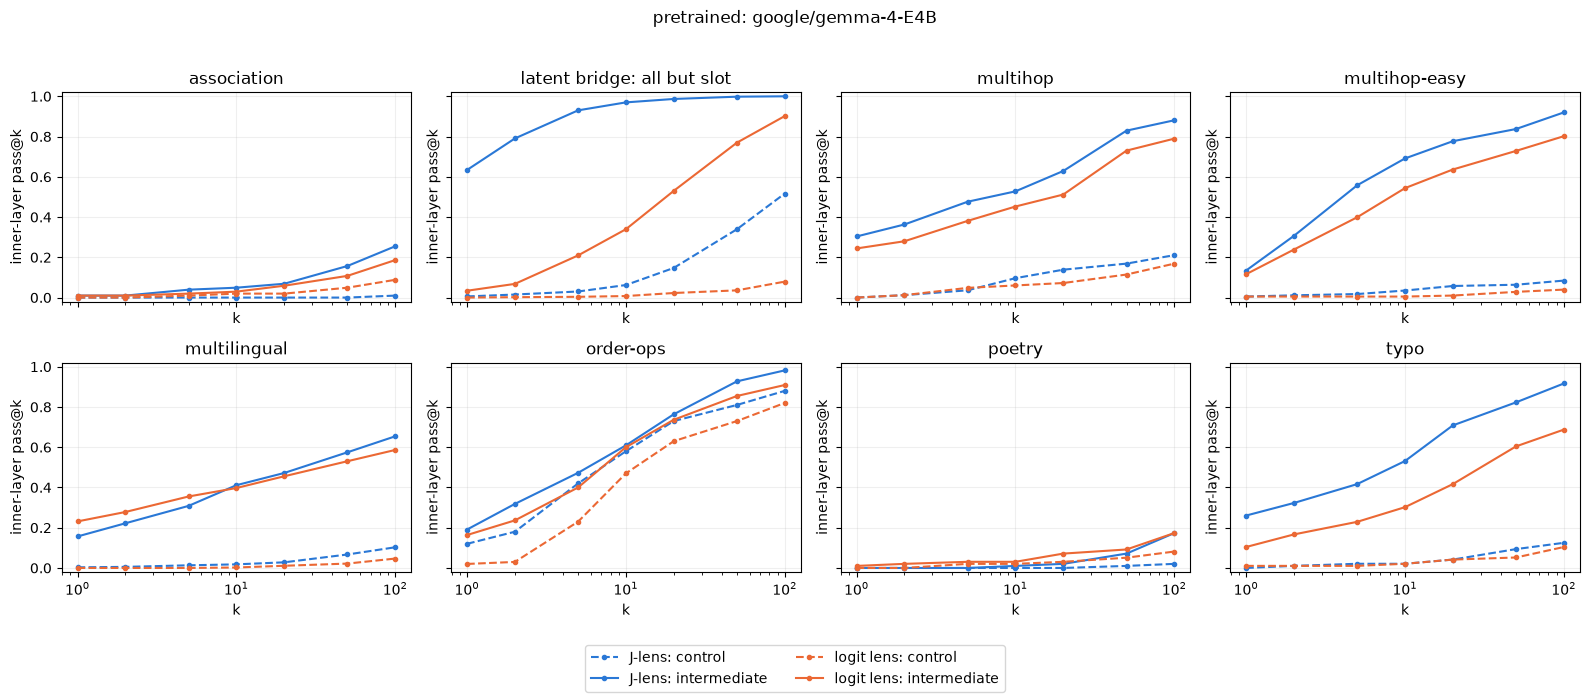

In [15]:
curve_tables = []
for scope in ["inner", "all blocks"]:
    bridge = latent_scores[
        latent_scores.subset.eq("all candidates") & latent_scores.dataset.eq("latent-bridge/all")
        & latent_scores.span.eq("all but slot") & latent_scores.scope.eq(scope)
    ].copy()
    bridge["dataset"] = "latent bridge: all but slot"
    curve_tables += [bridge, anthropic_scores[anthropic_scores.scope.eq(scope)]]
curves = pd.concat(curve_tables, ignore_index=True)
curves = curves[curves.kind.isin(["intermediate", "control"])]
auc_rows = []
for keys, group in curves.groupby(["dataset", "scope", "lens", "kind"]):
    group = group.sort_values("k")
    auc_rows.append(dict(zip(["dataset", "scope", "lens", "kind"], keys, strict=True),
                         auc=np.trapezoid(group.score, np.log(group.k)) / np.log(100)))
auc = pd.DataFrame(auc_rows)
display(auc[auc.kind.eq("intermediate")].pivot(
    index=["dataset", "scope"], columns="lens", values="auc",
).round(3))

plot_groups = list(curves[curves.scope.eq("inner")].groupby("dataset"))
n_plot_rows = (len(plot_groups) + 3) // 4
fig, axes = plt.subplots(n_plot_rows, 4, figsize=(16, 3.5 * n_plot_rows),
                         sharex=True, sharey=True, squeeze=False)
for ax, (dataset, group) in zip(axes.flat, plot_groups, strict=False):
    for (lens_name, kind), line in group.groupby(["lens", "kind"]):
        ax.plot(line.k, line.score, color=COLORS[lens_name],
                linestyle="-" if kind == "intermediate" else "--", marker="o", ms=3,
                label=f"{lens_name}: {kind}")
    ax.set(xscale="log", ylim=(-0.02, 1.02), title=dataset, xlabel="k", ylabel="inner-layer pass@k")
    ax.grid(alpha=0.2)
for ax in list(axes.flat)[len(plot_groups):]:
    ax.axis("off")
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2)
fig.suptitle(f"{SOURCE_MODE}: {run_model_id}")
fig.tight_layout(rect=(0, 0.09, 1, 0.96))
fig.savefig(RUN_DIR / "inner_pass_at_k.png", dpi=140)
plt.show()

## Paired bootstrap: what the intervals measure

These are **pointwise percentile intervals (95% by default)** for a fixed model, lens, scoring
rule, and setting. Resample complete prompt clusters with replacement, using the
same draws for every method and computing the method difference on each draw.
The original point estimate remains unchanged. No model passes or lens refits
are needed to change the bootstrap seed, confidence level, or resample count.

`status="ok"` means an interval was estimated. `degenerate` means the observed
bootstrap distribution is constant; its interval is deliberately left null.
In particular, 0 observed successes is **not** a demonstrated population rate
of zero. `too_few_clusters` and `no_supported_units` also have null intervals.
Coverage counts distinguish absent support from failed retrieval. No bootstrap
upper bound is inferred for an all-zero control.

Intervals assume the chosen clusters are independent and represent similar
benchmark examples. They do not cover new task families, lens fitting
variability, random-control seeds, or model nondeterminism. They do not correct
selection of the best setting on these data or simultaneous testing of many
datasets/settings. Primary settings stay fixed; sweeps are exploratory.


For ordinary retrieval, average supported word hits within an item and resample
items. For multihop-easy, average phrasings within `base_id`, retain related
base items in `group_id`, resample groups **within each family**, then average
families equally. Supported base items retain their original equal weights;
larger groups are not silently given the weight of one base item. Intervals
are conditional on the observed family mix. The source metadata hash is checked
before grouping old caches. Interval coverage tables retain unsupported units.

In [16]:
aggregate_bootstrap_path = RUN_DIR / "aggregate_bootstrap.pkl"
if aggregate_bootstrap_path.exists():
    bootstrap_ci = pd.read_pickle(aggregate_bootstrap_path)
    print("Restored aggregate bootstrap intervals.")
else:
    bootstrap_tables = []
    for span in LAYERWISE_SPANS:
        selected = span_words[span_words.span.eq(span) & span_words.kind.isin(["intermediate", "control"])].copy()
        selected["item"] = selected.dataset + ":" + selected.item
        selected["dataset"] = f"latent bridge: {span}"
        table = retrieval_bootstrap(selected, ks=K_VALUES, layers=INNER, **BOOTSTRAP_OPTIONS)
        bootstrap_tables.append(table.assign(span=span, subset="all candidates", split="all"))

    selected = anth_words[anth_words.kind.isin(["intermediate", "control"])]
    table = retrieval_bootstrap(selected, ks=K_VALUES, layers=INNER,
                                easy_metadata=easy_metadata, **BOOTSTRAP_OPTIONS)
    bootstrap_tables.append(table.assign(span="protocol position", subset="all", split="all"))
    for split in ["dev", "test"]:
        selected = easy_words[easy_words.split.eq(split) & easy_words.kind.isin(["intermediate", "control"])]
        if not selected.empty:
            table = retrieval_bootstrap(selected, ks=K_VALUES, layers=INNER,
                                        easy_metadata=easy_metadata, **BOOTSTRAP_OPTIONS)
            bootstrap_tables.append(table.assign(span="protocol position", subset="all", split=split))
    bootstrap_ci = pd.concat(bootstrap_tables, ignore_index=True).assign(scope="inner")

    temporary = aggregate_bootstrap_path.with_suffix(".tmp")
    bootstrap_ci.to_pickle(temporary)
    temporary.replace(aggregate_bootstrap_path)

# Check that uncertainty analysis preserves the existing benchmark estimand.
points = bootstrap_ci[bootstrap_ci.statistic.eq("arm") & bootstrap_ci.metric.eq("pass_at_k")
                      & bootstrap_ci.split.eq("all")]
expected = curves[curves.scope.eq("inner")][["dataset", "lens", "kind", "k", "score"]]
check = expected.merge(points, left_on=["dataset", "lens", "kind", "k"],
                       right_on=["dataset", "arm", "kind", "k"], validate="one_to_one")
assert len(check) == len(expected)
np.testing.assert_allclose(check.score, check.estimate, atol=1e-12, equal_nan=True)
display(bootstrap_ci[bootstrap_ci.k.eq(K) & bootstrap_ci.split.eq("all")][
    ["dataset", "kind", "statistic", "arm", "reference", "estimate", "ci_low", "ci_high",
     "status", "n_units", "n_clusters", "n_words_scored"]
].round(4))
display(bootstrap_ci[bootstrap_ci.metric.eq("log_k_auc") & bootstrap_ci.kind.eq("intermediate")
                     & bootstrap_ci.split.eq("all")][
    ["dataset", "statistic", "arm", "reference", "estimate", "ci_low", "ci_high", "status"]
].round(4))
bootstrap_ci.to_csv(RUN_DIR / "bootstrap_intervals.csv", index=False)

,dataset,kind,statistic,arm,reference,estimate,ci_low,ci_high,status,n_units,n_clusters,n_words_scored
9,latent bridge: subject,control,arm,J-lens,,0.0038,0.0000,0.0094,ok,530,530,530
10,latent bridge: subject,control,arm,logit lens,,0.0057,0.0000,0.0132,ok,530,530,530
11,latent bridge: subject,control,difference,J-lens,logit lens,-0.0019,-0.0113,0.0057,ok,530,530,530
33,latent bridge: subject,intermediate,arm,J-lens,,0.5057,0.4623,0.5491,ok,530,530,530
34,latent bridge: subject,intermediate,arm,logit lens,,0.1075,0.0830,0.1340,ok,530,530,530
35,latent bridge: subject,intermediate,difference,J-lens,logit lens,0.3981,0.3566,0.4415,ok,530,530,530
57,latent bridge: country token,control,arm,J-lens,,0.0340,0.0189,0.0491,ok,530,530,530
58,latent bridge: country token,control,arm,logit lens,,0.0000,NaN,NaN,degenerate,530,530,530
59,latent bridge: country token,control,difference,J-lens,logit lens,0.0340,0.0189,0.0491,ok,530,530,530
81,latent bridge: country token,intermediate,arm,J-lens,,0.8189,0.7868,0.8509,ok,530,530,530


,dataset,statistic,arm,reference,estimate,ci_low,ci_high,status
45,latent bridge: subject,arm,J-lens,,0.4967,0.4699,0.5236,ok
46,latent bridge: subject,arm,logit lens,,0.1224,0.1026,0.1429,ok
47,latent bridge: subject,difference,J-lens,logit lens,0.3743,0.3493,0.3993,ok
93,latent bridge: country token,arm,J-lens,,0.7747,0.7491,0.8004,ok
94,latent bridge: country token,arm,logit lens,,0.0319,0.0230,0.0417,ok
95,latent bridge: country token,difference,J-lens,logit lens,0.7428,0.7169,0.7684,ok
141,latent bridge: all but slot,arm,J-lens,,0.9165,0.9030,0.9292,ok
142,latent bridge: all but slot,arm,logit lens,,0.3972,0.3737,0.4208,ok
143,latent bridge: all but slot,difference,J-lens,logit lens,0.5193,0.4954,0.5436,ok
189,association,arm,J-lens,,0.0753,0.0427,0.1128,ok


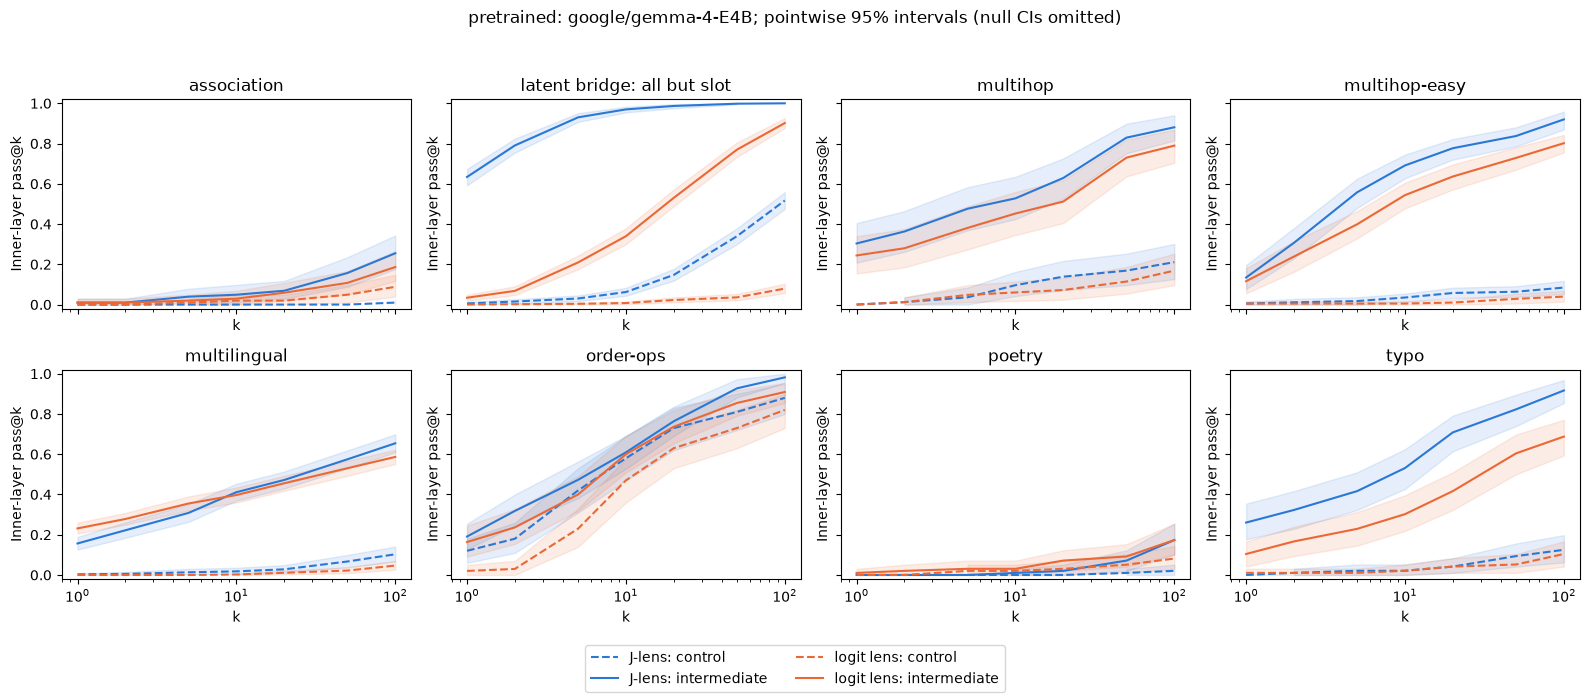

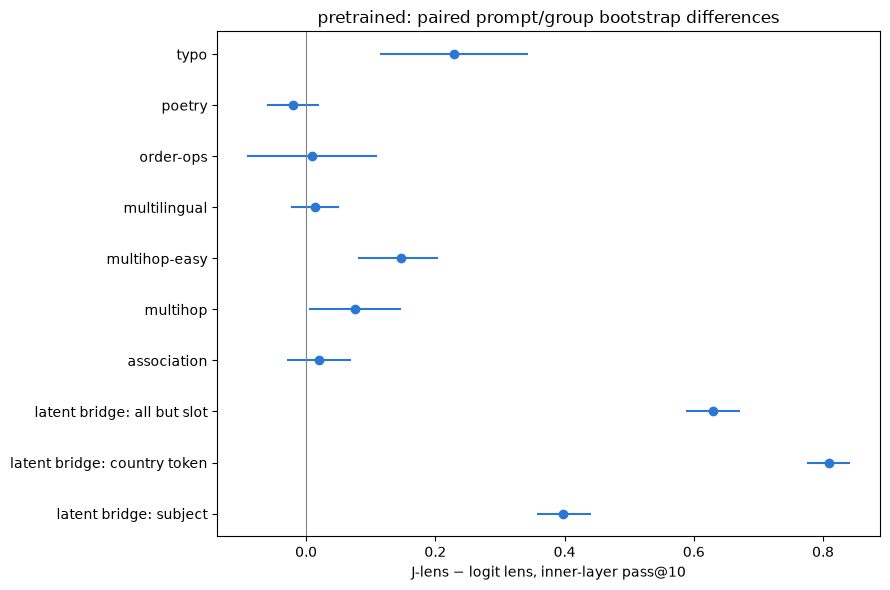

In [17]:
primary_curves = bootstrap_ci[bootstrap_ci.statistic.eq("arm") & bootstrap_ci.metric.eq("pass_at_k")
                             & bootstrap_ci.split.eq("all")
                             & ~bootstrap_ci.dataset.isin(["latent bridge: subject", "latent bridge: country token"])]
groups = list(primary_curves.groupby("dataset"))
fig, axes = plt.subplots((len(groups) + 3) // 4, 4, figsize=(16, 7), sharex=True, sharey=True, squeeze=False)
for ax, (dataset, group) in zip(axes.flat, groups, strict=False):
    for (arm, kind), line in group.groupby(["arm", "kind"]):
        line = line.sort_values("k")
        ax.plot(line.k, line.estimate, color=COLORS[arm], linestyle="-" if kind == "intermediate" else "--",
                label=f"{arm}: {kind}")
        ax.fill_between(line.k.to_numpy(dtype=float), line.ci_low.to_numpy(dtype=float),
                        line.ci_high.to_numpy(dtype=float), color=COLORS[arm], alpha=.12)
    ax.set(title=dataset, xscale="log", xlabel="k", ylabel="Inner-layer pass@k", ylim=(-.02, 1.02))
for ax in list(axes.flat)[len(groups):]:
    ax.axis("off")
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2)
fig.suptitle(f"{SOURCE_MODE}: {run_model_id}; pointwise "
             f"{100 * BOOTSTRAP_OPTIONS['confidence']:g}% intervals (null CIs omitted)")
fig.tight_layout(rect=(0, .08, 1, .95))
fig.savefig(RUN_DIR / "bootstrap_pass_at_k.png", dpi=160)
fig.savefig(RUN_DIR / "bootstrap_pass_at_k.svg")
plt.show()

differences = bootstrap_ci[bootstrap_ci.statistic.eq("difference") & bootstrap_ci.kind.eq("intermediate")
                          & bootstrap_ci.k.eq(K) & bootstrap_ci.split.eq("all")]
fig, ax = plt.subplots(figsize=(9, 6))
for y, row in enumerate(differences.itertuples()):
    ax.scatter(row.estimate, y, color="#2a78d6")
    if row.status == "ok":
        ax.hlines(y, row.ci_low, row.ci_high, color="#2a78d6")
    else:
        ax.annotate(row.status, (row.estimate, y), xytext=(5, 4), textcoords="offset points", fontsize=8)
ax.set_yticks(range(len(differences)), differences.dataset)
ax.axvline(0, color="gray", linewidth=.8)
ax.set(xlabel=f"J-lens − logit lens, inner-layer pass@{K}",
       title=f"{SOURCE_MODE}: paired prompt/group bootstrap differences")
fig.tight_layout()
fig.savefig(RUN_DIR / "bootstrap_paired_differences.png", dpi=160)
fig.savefig(RUN_DIR / "bootstrap_paired_differences.svg")
plt.show()

## Readouts at each layer, with pointwise confidence intervals

Each score below uses **one block**, with no minimum over layers. Latent-bridge
ranks still take the minimum over positions in the chosen span; single-position
datasets retain their protocol position. All blocks, including the shared final
block, are shown. Depth is `layer / (N_LAYERS - 1)`; the export also retains the
zero-based block index and total block count.

Word/item weighting and multihop-easy phrasing/base/family grouping match the
aggregate analysis. Both lenses use the same prompt/group resamples, and the
same seed preserves those draws across blocks. Shading shows pointwise intervals
(default 95%), **not simultaneous coverage** across depth. Thin vertical lines
show intervals at individual blocks, including isolated valid intervals.

Lines show intermediate and control estimates. Missing intervals are omitted
and retain their explicit `status` in the exported data. The paired-difference
figure is calculated from paired resamples, not by subtracting CI endpoints.
The shared final block must have a zero paired difference wherever supported.
Figures show all candidates and all splits; the full table also includes
multihop-easy dev/test results and log-k AUC at each block.


In [18]:
layerwise_bootstrap_path = RUN_DIR / "layerwise_bootstrap.pkl"
if layerwise_bootstrap_path.exists():
    layerwise_ci = pd.read_pickle(layerwise_bootstrap_path)
    print("Restored per-layer bootstrap intervals; no resampling or model passes.")
else:
    layerwise_tables = []
    for span in LAYERWISE_SPANS:
        selected = span_words[
            span_words.span.eq(span) & span_words.kind.isin(["intermediate", "control"])
        ].copy()
        selected["item"] = selected.dataset + ":" + selected.item
        selected["dataset"] = f"latent bridge: {span}"
        print(f"Bootstrapping {N_LAYERS} layers: latent bridge, {span}")
        table = retrieval_bootstrap_by_layer(
            selected, n_layers=N_LAYERS, ks=K_VALUES, **BOOTSTRAP_OPTIONS,
        )
        layerwise_tables.append(table.assign(span=span, subset="all candidates", split="all"))

    selected = anth_words[anth_words.kind.isin(["intermediate", "control"])]
    print(f"Bootstrapping {N_LAYERS} layers: single-position datasets")
    table = retrieval_bootstrap_by_layer(
        selected, n_layers=N_LAYERS, ks=K_VALUES,
        easy_metadata=easy_metadata, **BOOTSTRAP_OPTIONS,
    )
    layerwise_tables.append(table.assign(span="protocol position", subset="all", split="all"))
    for split in ["dev", "test"]:
        selected = easy_words[
            easy_words.split.eq(split) & easy_words.kind.isin(["intermediate", "control"])
        ]
        if not selected.empty:
            table = retrieval_bootstrap_by_layer(
                selected, n_layers=N_LAYERS, ks=K_VALUES,
                easy_metadata=easy_metadata, **BOOTSTRAP_OPTIONS,
            )
            layerwise_tables.append(table.assign(span="protocol position", subset="all", split=split))
    layerwise_ci = pd.concat(layerwise_tables, ignore_index=True)
    temporary = layerwise_bootstrap_path.with_suffix(".tmp")
    layerwise_ci.to_pickle(temporary)
    temporary.replace(layerwise_bootstrap_path)

final_differences = layerwise_ci[
    layerwise_ci.is_final_layer & layerwise_ci.statistic.eq("difference")
].estimate.dropna()
np.testing.assert_allclose(final_differences, 0, atol=1e-12)
display(layerwise_ci.groupby(["statistic", "status"]).size().rename("rows").to_frame())


Bootstrapping 42 layers: latent bridge, subject


Bootstrapping 42 layers: latent bridge, country token


Bootstrapping 42 layers: latent bridge, all but slot


Bootstrapping 42 layers: single-position datasets


rows
statistic  status           
arm        degenerate  10670
           ok           5458
difference degenerate   4356
           ok           3708

### Plotting data and later model comparisons

`layerwise_bootstrap_intervals.csv` contains all per-layer pass@k and log-k AUC
estimates, CIs, paired differences, split labels, and support/cluster counts.
`layerwise_plot_data.csv` contains **exactly the rows used by the two figures
below**: pass@`K`, all splits, every plotted span/dataset and both statistics.
`bootstrap_intervals.csv` retains the original inner-layer analysis with the same
model identity columns. Values are rates on [0, 1] (differences on [-1, 1]); the
plots use `depth_percent`, which is on [0, 100]. CSV values are not rounded.

The files record the source model/revision, dtype, BOS policy, lens identity,
dataset hash, source-cache hash, and analysis ID. Full fitting and scoring
provenance remains in `analysis_manifest.json`. In cache mode these fields come
from the saved source manifest, not the notebook's current model defaults.

To combine model runs later, concatenate their exports without averaging them:

```python
paths = [Path("model_a/layerwise_plot_data.csv"), Path("model_b/layerwise_plot_data.csv")]
combined = pd.concat([pd.read_csv(path) for path in paths], ignore_index=True)
# Plot each model_id/analysis_id separately against depth_percent or layer.
```

Match dataset, span, subset, split, kind, metric, k, statistic, and confidence
before comparing curves; retain `analysis_id` to distinguish runs of the same
model. Normalized depth aligns axes, not representations. Tokenizer support,
BOS/scoring rules, and fit provenance can differ across models. A concatenated
CSV does not itself provide a paired confidence interval between models.


In [19]:
export_identity = {
    "export_schema": 1,
    "analysis_id": RUN_DIR.name,
    "model_id": manifest["model"],
    "model_revision": manifest["revision"],
    "dtype": manifest["dtype"],
    "bos_policy": manifest["bos_policy"],
    "source_mode": manifest["mode"],
    "lens_sha256_or_identity": manifest.get("lens_sha256_or_identity", "unknown"),
    "evals_sha256": manifest["evals_sha256"],
    "source_cache_sha256": analysis_manifest["source_cache_sha256"],
    "scoring": manifest.get("scoring", "unknown"),
}
layerwise_export = layerwise_ci.assign(**export_identity)
leading_columns = [
    *export_identity, "dataset", "span", "subset", "split", "kind", "metric", "k",
    "statistic", "arm", "reference", "layer", "n_layers", "depth_fraction",
    "depth_percent", "is_final_layer", "estimate", "ci_low", "ci_high", "status",
]
layerwise_export = layerwise_export[
    leading_columns + [c for c in layerwise_export if c not in leading_columns]
].sort_values(["dataset", "span", "split", "kind", "metric", "k", "statistic", "arm", "layer"])
layerwise_plot_data = layerwise_export[
    layerwise_export.metric.eq("pass_at_k") & layerwise_export.k.eq(K)
    & layerwise_export.split.eq("all")
].copy()
layerwise_export.to_csv(RUN_DIR / "layerwise_bootstrap_intervals.csv", index=False)
layerwise_plot_data.to_csv(RUN_DIR / "layerwise_plot_data.csv", index=False)
bootstrap_ci.assign(**export_identity).to_csv(RUN_DIR / "bootstrap_intervals.csv", index=False)
display(layerwise_plot_data[[
    "model_id", "dataset", "kind", "statistic", "arm", "layer", "depth_percent",
    "estimate", "ci_low", "ci_high", "status", "n_words_scored", "n_clusters",
]].head(24))
for name in ["layerwise_bootstrap_intervals.csv", "layerwise_plot_data.csv", "analysis_manifest.json"]:
    print(name, "->", RUN_DIR / name)
if PRINT_LAYERWISE_CSV:
    print(layerwise_plot_data.to_csv(index=False))


,model_id,dataset,kind,statistic,arm,layer,depth_percent,estimate,ci_low,ci_high,status,n_words_scored,n_clusters
6057,google/gemma-4-E4B,association,control,arm,J-lens,0,0.000000,0.0,NaN,NaN,degenerate,102,102
6393,google/gemma-4-E4B,association,control,arm,J-lens,1,2.439024,0.0,NaN,NaN,degenerate,102,102
6729,google/gemma-4-E4B,association,control,arm,J-lens,2,4.878049,0.0,NaN,NaN,degenerate,102,102
7065,google/gemma-4-E4B,association,control,arm,J-lens,3,7.317073,0.0,NaN,NaN,degenerate,102,102
7401,google/gemma-4-E4B,association,control,arm,J-lens,4,9.756098,0.0,NaN,NaN,degenerate,102,102
7737,google/gemma-4-E4B,association,control,arm,J-lens,5,12.195122,0.0,NaN,NaN,degenerate,102,102
8073,google/gemma-4-E4B,association,control,arm,J-lens,6,14.634146,0.0,NaN,NaN,degenerate,102,102
8409,google/gemma-4-E4B,association,control,arm,J-lens,7,17.073171,0.0,NaN,NaN,degenerate,102,102
8745,google/gemma-4-E4B,association,control,arm,J-lens,8,19.512195,0.0,NaN,NaN,degenerate,102,102
9081,google/gemma-4-E4B,association,control,arm,J-lens,9,21.951220,0.0,NaN,NaN,degenerate,102,102


layerwise_bootstrap_intervals.csv -> /workspace/jacobian-lens-gpt2/runs/model-agnostic-lens-benchmark/bootstrap-layerwise/7ebf631085b90dcf728c/layerwise_bootstrap_intervals.csv
layerwise_plot_data.csv -> /workspace/jacobian-lens-gpt2/runs/model-agnostic-lens-benchmark/bootstrap-layerwise/7ebf631085b90dcf728c/layerwise_plot_data.csv
analysis_manifest.json -> /workspace/jacobian-lens-gpt2/runs/model-agnostic-lens-benchmark/bootstrap-layerwise/7ebf631085b90dcf728c/analysis_manifest.json


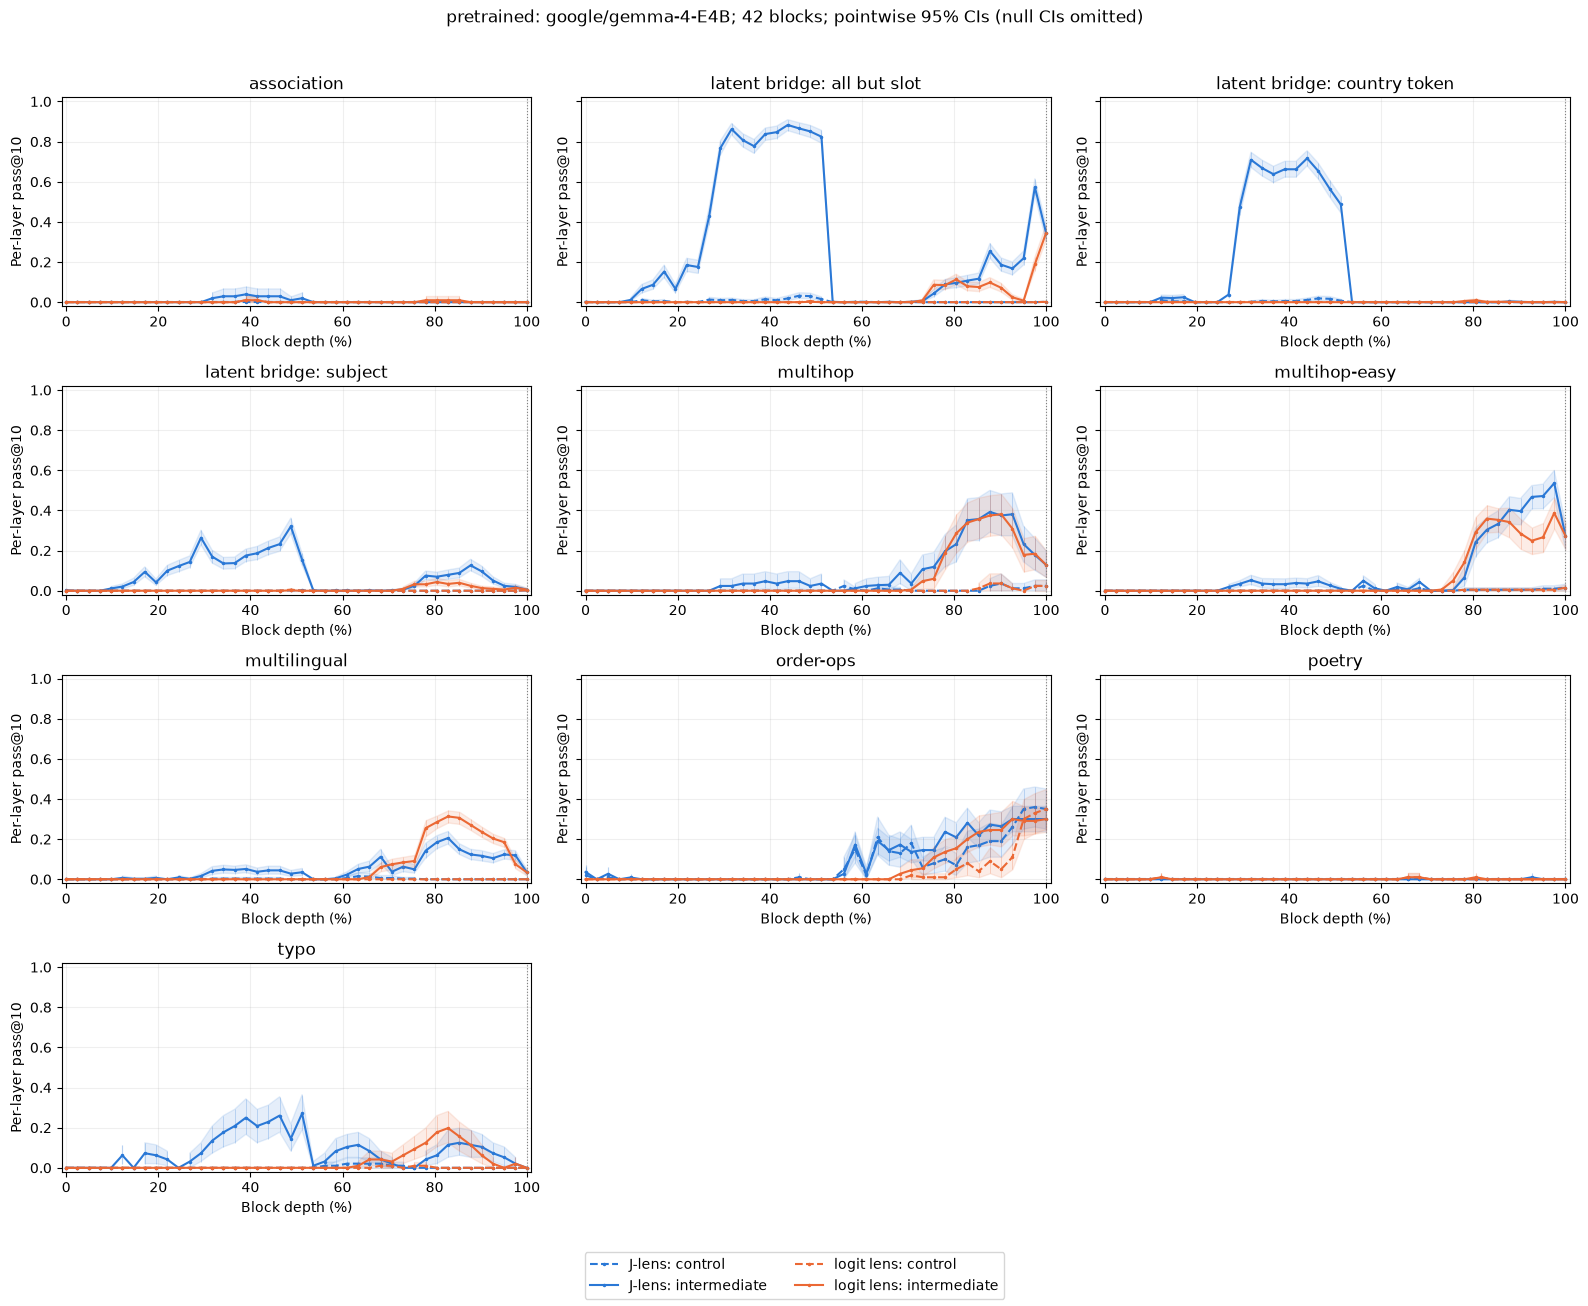

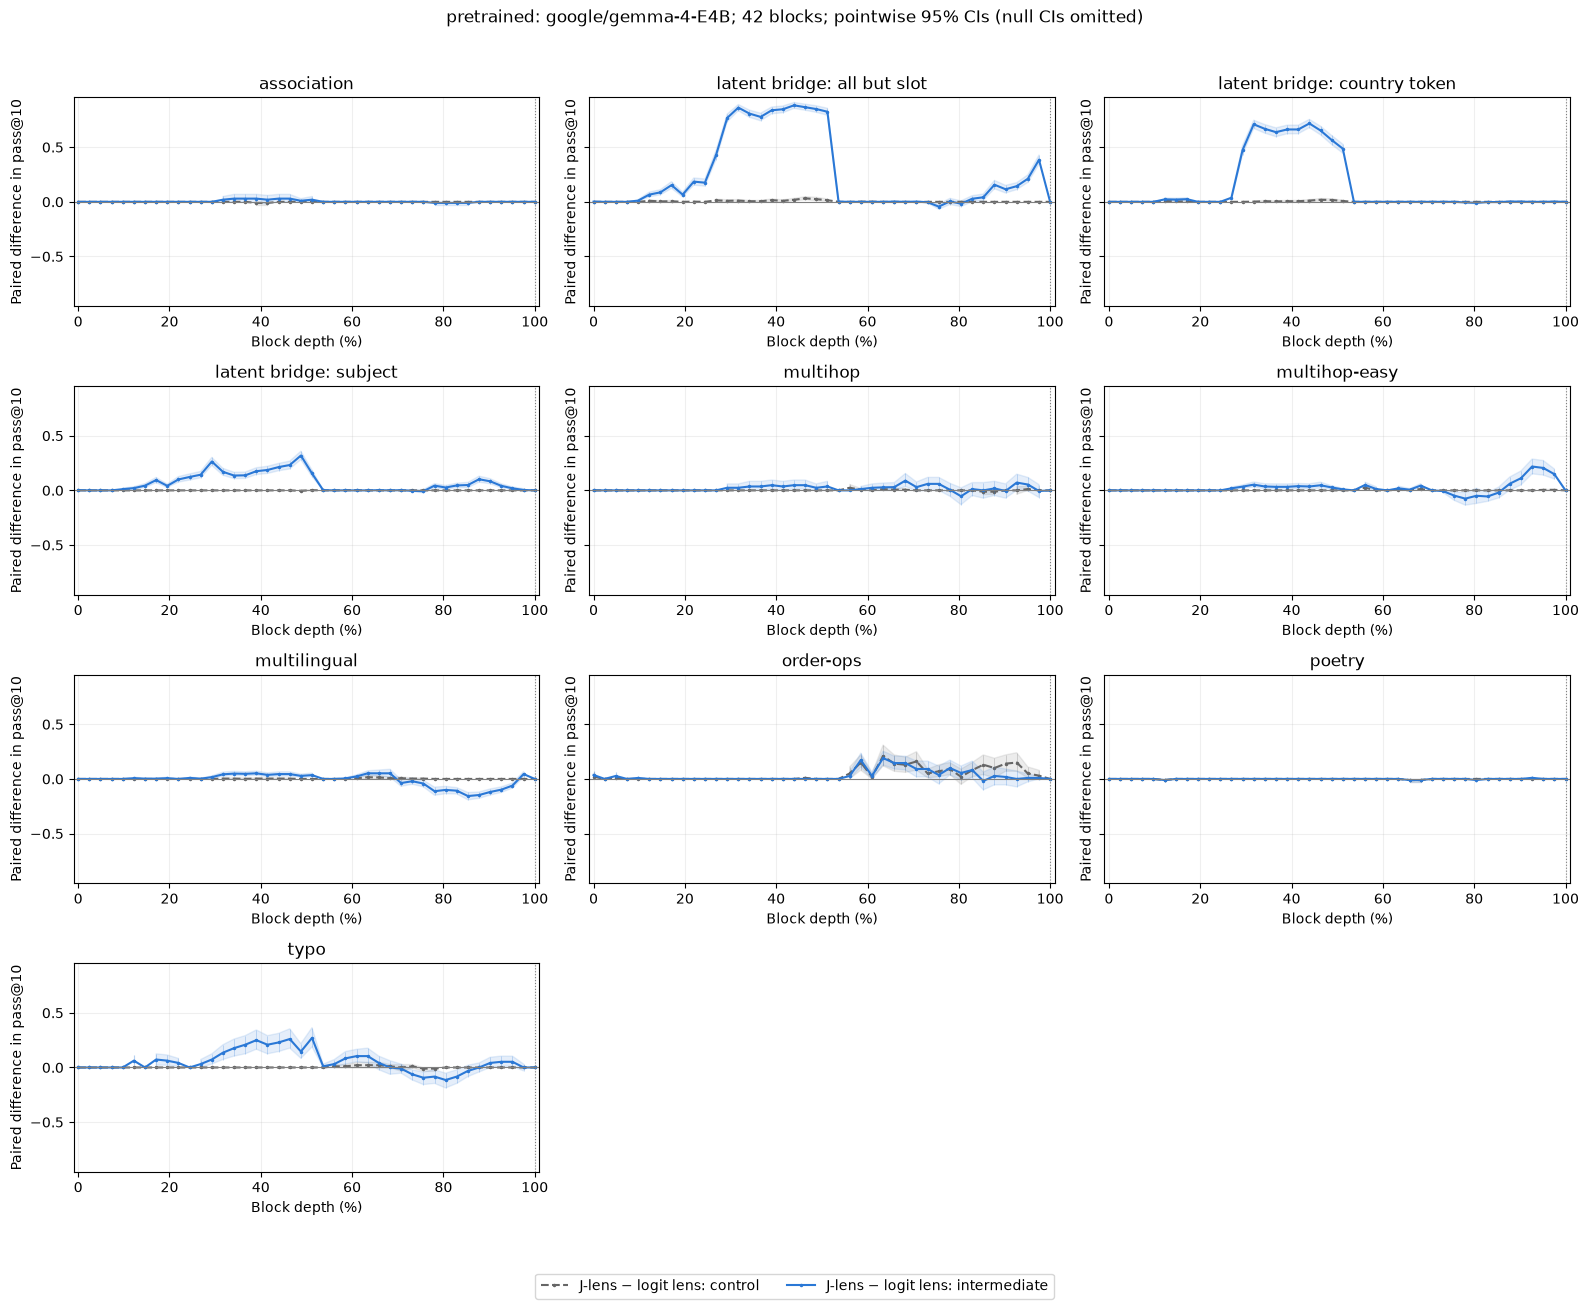

In [20]:
for statistic, filename in [
    ("arm", "bootstrap_layerwise_readouts"),
    ("difference", "bootstrap_layerwise_differences"),
]:
    selected = layerwise_plot_data[layerwise_plot_data.statistic.eq(statistic)]
    groups = list(selected.groupby("dataset"))
    if statistic == "difference":
        bounds = selected[["estimate", "ci_low", "ci_high"]].to_numpy(dtype=float)
        # Keep floating-point zero differences from filling the vertical scale.
        difference_limit = max(.05, 1.05 * np.abs(bounds[np.isfinite(bounds)]).max(initial=0))
    n_rows = (len(groups) + 2) // 3
    fig, axes = plt.subplots(n_rows, 3, figsize=(16, 3.3 * n_rows),
                             sharex=True, sharey=True, squeeze=False)
    for ax, (dataset, group) in zip(axes.flat, groups, strict=False):
        for (arm, kind), line in group.groupby(["arm", "kind"]):
            line = line.sort_values("layer")
            color = COLORS[arm] if statistic == "arm" else ("#2a78d6" if kind == "intermediate" else "#666666")
            label = f"{arm}: {kind}" if statistic == "arm" else f"J-lens − logit lens: {kind}"
            x = line.depth_percent.to_numpy(dtype=float)
            lo = line.ci_low.where(line.status.eq("ok")).to_numpy(dtype=float)
            hi = line.ci_high.where(line.status.eq("ok")).to_numpy(dtype=float)
            ax.plot(x, line.estimate, color=color, linestyle="-" if kind == "intermediate" else "--",
                    marker=".", ms=3, label=label)
            ax.fill_between(x, lo, hi, color=color, alpha=.12)
            valid = np.isfinite(lo) & np.isfinite(hi)
            ax.vlines(x[valid], lo[valid], hi[valid], color=color, alpha=.25, linewidth=.7)
        if statistic == "difference":
            ax.axhline(0, color="gray", linewidth=.8)
            ax.set_ylim(-difference_limit, difference_limit)
        ax.axvline(100, color="gray", linestyle=":", linewidth=.8)
        ax.set(title=dataset, xlabel="Block depth (%)", xlim=(-1, 101),
               ylabel=f"Per-layer pass@{K}" if statistic == "arm" else f"Paired difference in pass@{K}")
        if statistic == "arm":
            ax.set_ylim(-.02, 1.02)
        ax.tick_params(axis="x", labelbottom=True)
        ax.grid(alpha=.2)
    for ax in list(axes.flat)[len(groups):]:
        ax.axis("off")
    legend = {}
    for ax in axes.flat:
        handles, labels = ax.get_legend_handles_labels()
        legend.update(zip(labels, handles, strict=True))
    fig.legend(legend.values(), legend.keys(), loc="lower center", ncol=2)
    fig.suptitle(f"{SOURCE_MODE}: {run_model_id}; {N_LAYERS} blocks; pointwise "
                 f"{100 * BOOTSTRAP_OPTIONS['confidence']:g}% CIs (null CIs omitted)")
    fig.tight_layout(rect=(0, .055, 1, .965))
    fig.savefig(RUN_DIR / f"{filename}.png", dpi=160)
    fig.savefig(RUN_DIR / f"{filename}.svg")
    plt.show()


### Example position map

This uses one actual tokenization, avoiding an assumption that different
subjects or tokenizers share the same template-token columns. The map shows
ranks for one prompt and does not represent a confidence interval.


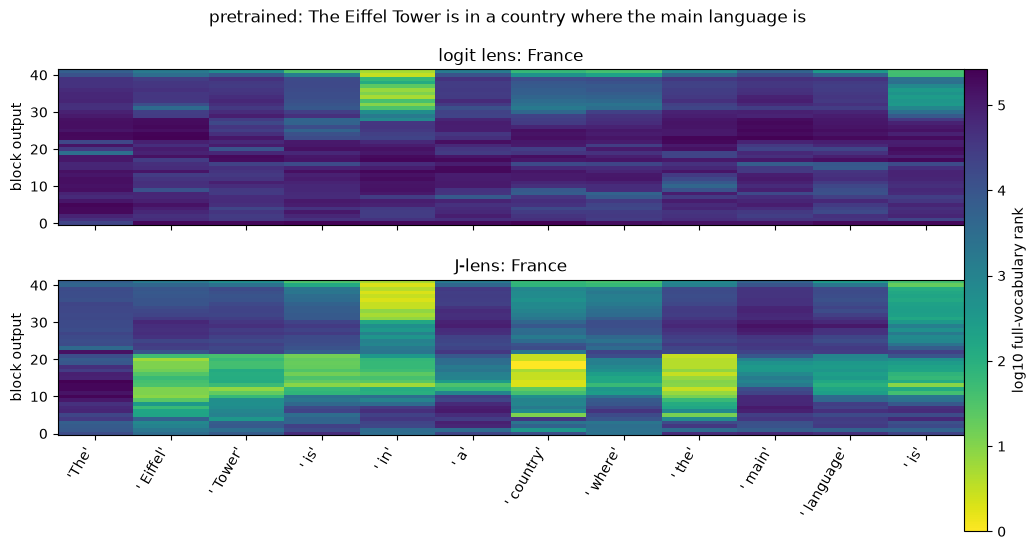

In [21]:
example = position_words[position_words.kind.eq("intermediate") & position_words.ranks.notna()].head(1)
if not example.empty:
    selected = example.iloc[0]
    item = latent_items[latent_items.dataset.eq(selected.dataset) & latent_items.item.eq(selected["item"])].iloc[0]
    rows = position_words[position_words.dataset.eq(selected.dataset) & position_words.item.eq(selected["item"])
                          & position_words.kind.eq("intermediate")]
    fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
    for ax, row in zip(axes, rows.itertuples(), strict=True):
        image = ax.imshow(np.log10(row.ranks), aspect="auto", origin="lower", vmin=0,
                          vmax=max(1, np.log10(config.get_text_config().vocab_size)), cmap="viridis_r")
        ax.set(title=f"{row.lens}: {row.word}", ylabel="block output")
    labels = [repr(tokenizer.decode([item.ids[p]])) for p in selected.positions]
    axes[-1].set_xticks(range(len(labels)), labels, rotation=60, ha="right")
    fig.colorbar(image, ax=axes, label="log10 full-vocabulary rank", fraction=0.025)
    fig.suptitle(f"{RUN_MODE}: {item.prompt}")
    fig.subplots_adjust(bottom=0.27, hspace=0.35, right=0.88)
    fig.savefig(RUN_DIR / "position_example.png", dpi=140, bbox_inches="tight")
    plt.show()

## Paired comparisons and examples

A positive log10 rank gain means the J-lens finds the intermediate at a better best inner-layer rank. Latent-bridge pairs use all-but-slot positions; Anthropic pairs use the prescribed single position. The table counts word occurrences, while pass@k above weights items equally.

Multihop-easy also uses the final-token readout here. Its paraphrases are counted separately in this diagnostic; use the grouped scores above for the dataset-level comparison.

In [22]:
comparison_words = pd.concat([
    span_words[span_words.span.eq("all but slot")], anth_words,
], ignore_index=True)
comparison_words = comparison_words[
    comparison_words.kind.eq("intermediate") & comparison_words.ranks.notna()
].copy()
comparison_words["inner_best"] = comparison_words.ranks.map(lambda r: r[:-1].min())
paired = comparison_words.pivot(
    index=["dataset", "item", "word", "role"], columns="lens", values="inner_best",
)
paired["log10 gain"] = np.log10(paired["logit lens"]) - np.log10(paired["J-lens"])
paired["winner"] = np.select(
    [paired["J-lens"] < paired["logit lens"], paired["J-lens"] > paired["logit lens"]],
    ["J-lens", "logit lens"], default="tie",
)
paired_summary = paired.groupby("dataset").winner.value_counts().unstack(fill_value=0)
display(paired_summary.reindex(columns=["J-lens", "logit lens", "tie"], fill_value=0))
display(paired.sort_values("log10 gain", ascending=False).head(8))
display(paired.sort_values("log10 gain").head(8))

winner,J-lens,logit lens,tie
dataset,,,
association,66,36,0
latent-bridge/brand,79,0,4
latent-bridge/city,112,0,7
latent-bridge/food,101,0,2
latent-bridge/landmark,103,0,5
latent-bridge/person,104,6,7
multihop,55,15,24
multihop-easy,135,31,34
multilingual,188,186,54


lens                                             J-lens  logit lens  log10 gain  winner
dataset       item                 word    role                                        
multilingual  danish-color-ocean   Danish  0          1        2969    3.472610  J-lens
multihop      month-1-godof        January 0          1        1531    3.184975  J-lens
multilingual  french-body-walk     French  0          2        2584    3.111263  J-lens
typo          typo-another         another 0          1        1169    3.067815  J-lens
multilingual  arabic-color-blood   Arabic  0          2        2216    3.044540  J-lens
              hindi-color-snow     Hindi   0          1         761    2.881385  J-lens
multihop-easy horse-legs-v2        horse   0          3        2274    2.879669  J-lens
multilingual  spanish-opposite-big Spanish 0          6        3970    2.820639  J-lens

lens                                             J-lens  logit lens  log10 gain      winner
dataset       item                word     role                                            
association   code-h              code     0       3735           3   -3.095169  logit lens
multilingual  persian-color-blood red      3        913           1   -2.960471  logit lens
poetry        couplet-stone-bone  bone     0       1073           3   -2.553478  logit lens
              couplet-flame-name  name     0       2668          12   -2.347005  logit lens
association   china-h             China    0       4204          19   -2.344909  logit lens
poetry        couplet-sold-told   told     0        189           1   -2.276462  logit lens
multihop-easy elephant-legs-v2    elephant 0        132           1   -2.120574  logit lens
poetry        couplet-trap-map    map      0       3372          47   -1.855790  logit lens

## Conclusions

The generated statements below describe the active run. A visibility advantage is evidence about a readout, not causal evidence that the model used that intermediate. Position sweeps offer more opportunities for a hit than a single-position protocol, so raw scores across the two suites are not directly comparable. Historical GPT-2 selection, current-model correctness, tokenizer coverage and fitting corpus can all change the comparison.

In [23]:
lines = []
if SOURCE_MODE == "smoke":
    lines.append("**Offline smoke only:** random tiny Llama plus identity Jacobians. "
                 "All paired ranks match; these results validate execution, not trained-model quality.")
else:
    lines.append(f"**Model:** `{run_model_id}` at `{resolved_revision}`; dtype `{run_dtype}`; BOS `{BOS_POLICY}`.")
    lines.append("Fitting provenance is recorded in the run manifest; unknown fields remain unverified.")
for dataset, group in curves[curves.scope.eq("inner") & curves.kind.eq("intermediate")
                              & curves.k.eq(K)].groupby("dataset"):
    rates = group.set_index("lens").score
    j, l = rates.get("J-lens", np.nan), rates.get("logit lens", np.nan)
    if pd.isna(j) or pd.isna(l):
        lines.append(f"{dataset}: no supported intermediate observations; pass@{K} unavailable.")
    else:
        lines.append(f"{dataset}: inner-layer pass@{K}, J-lens {j:.1%}, logit lens {l:.1%}; "
                     f"difference {100 * (j - l):+.1f} percentage points.")
lines.append("Multihop-easy uses phrasing/base/family aggregation; its easy label does not establish model success.")
lines.append("Anthropic protocol scores including the shared final block are reported separately above. "
             "Consult coverage and target support before comparing models.")
display(Markdown("\n\n".join(lines)))
latent_scores.to_csv(RUN_DIR / "latent_scores.csv", index=False)
anthropic_scores.to_csv(RUN_DIR / "anthropic_scores.csv", index=False)
easy_scores.to_csv(RUN_DIR / "multihop_easy_scores.csv", index=False)
auc.to_csv(RUN_DIR / "auc.csv", index=False)
accuracy.to_csv(RUN_DIR / "answer_accuracy.csv")
print("Rank cache, provenance, tables and figures:", RUN_DIR.relative_to(REPO))

**Model:** `google/gemma-4-E4B` at `411aa17b749aa952df1359d2dcea73917a544d9a`; dtype `torch.bfloat16`; BOS `tokenizer`.

Fitting provenance is recorded in the run manifest; unknown fields remain unverified.

association: inner-layer pass@10, J-lens 4.9%, logit lens 2.9%; difference +2.0 percentage points.

latent bridge: all but slot: inner-layer pass@10, J-lens 97.0%, logit lens 34.0%; difference +63.0 percentage points.

multihop: inner-layer pass@10, J-lens 52.8%, logit lens 45.2%; difference +7.5 percentage points.

multihop-easy: inner-layer pass@10, J-lens 69.1%, logit lens 54.4%; difference +14.7 percentage points.

multilingual: inner-layer pass@10, J-lens 41.1%, logit lens 39.7%; difference +1.4 percentage points.

order-ops: inner-layer pass@10, J-lens 60.9%, logit lens 60.0%; difference +0.9 percentage points.

poetry: inner-layer pass@10, J-lens 1.0%, logit lens 3.1%; difference -2.0 percentage points.

typo: inner-layer pass@10, J-lens 53.1%, logit lens 30.2%; difference +22.9 percentage points.

Multihop-easy uses phrasing/base/family aggregation; its easy label does not establish model success.

Anthropic protocol scores including the shared final block are reported separately above. Consult coverage and target support before comparing models.

Rank cache, provenance, tables and figures: runs/model-agnostic-lens-benchmark/bootstrap-layerwise/7ebf631085b90dcf728c


## Conclusions of this version

The committed smoke run verifies that identity J-lens and logit-lens estimates
agree at every block and that paired zero differences have null intervals with
an explicit degeneracy/coverage status. The final output is shared by both
lenses. Trained-model conclusions require a pretrained run or its saved ranks.

The new figures distinguish readout quality at each layer from the original
best-inner-layer score. Report paired differences alongside readout curves,
control words, coverage, and independent-cluster counts. Intervals are pointwise;
choosing favorable layers after inspection remains exploratory.

The exact graphing rows and the full per-layer table are exported with model
and analysis identity, block indices, and normalized depth. These can be
concatenated for later model comparisons without rerunning model inference.
Model passes and both bootstrap analyses are cached in separate artifacts.
